# NCA Parent ML — raw-plus-ratio IA75 with K=5 vegetation labels

This notebook tests **75 predictors** from annual K2 harmonic fits for 15 optical variables: raw baseline (β₀), raw amplitudes (A₁ and A₂), relative seasonal amplitude (A₁/β₀), and relative harmonic content (A₂/A₁). No landscape-wide annual z-score parameters are used.

The supervised response labels, grouped validation, K24 diagnostic classification, temporal transfer test, and mapping workflow are retained. Comparisons with the former annual-z notebook must be treated as **comparisons of predictor representations**, not just relabeling experiments.

Ratios with negligible denominators are undefined/unstable and are excluded using explicit tolerances. See the configuration cell.


In [21]:
# =============================================================================
# 0. IMPORTS / PATHS / SETTINGS
# =============================================================================

from pathlib import Path
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from IPython.display import display

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 280)


# -----------------------------------------------------------------------------
# INPUTS
# -----------------------------------------------------------------------------

VEG_TRAINING_CSV = Path(
    r"A:\NCA_DATA\Validation\Supervised_State_Classification"
    r"\FieldVeg_K2_IA45_Training.csv"
)

K5_ASSIGNMENTS_CSV = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived"
    r"\NCA_FCM_K5_m1p33_parent_assignments.csv"
)


K24_ASSIGNMENTS_CSV = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters"
    r"\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv"
)

HARMONIC_ROOT = Path(
    r"A:\NCA_DATA\S2_Harmonics"
)

KEEP_MASK = Path(
    r"C:\NCA_DATA\templates\Masks\NCA_keepMask_v2.tif"
)


# -----------------------------------------------------------------------------
# OUTPUT — completely separate from K8 products
# -----------------------------------------------------------------------------

OUTPUT_DIR = Path(
    r"C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA75_K5"
)

ALLOW_OVERWRITE = True

if OUTPUT_DIR.exists():
    existing_files = [
        p
        for p in OUTPUT_DIR.rglob("*")
        if p.is_file()
    ]

    if existing_files and not ALLOW_OVERWRITE:
        raise FileExistsError(
            "K5 output directory already contains files. "
            "Stopping rather than overwriting an existing run.\n"
            f"Set ALLOW_OVERWRITE=True only if replacement is intentional.\n\n"
            f"{OUTPUT_DIR}"
        )

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# -----------------------------------------------------------------------------
# ANALYSIS SETTINGS
# -----------------------------------------------------------------------------

# Include 2026 automatically for mapping once its expected K2 raster exists.
# The earlier years remain mandatory in the raster availability checks.
MAP_2026_IF_AVAILABLE = True
RASTER_2026 = HARMONIC_ROOT / "2026" / "2026_K2_InterceptAmpPhase_nobs_RMSE.tif"
YEARS_TO_MAP = list(range(2016, 2026))
if MAP_2026_IF_AVAILABLE and RASTER_2026.exists():
    YEARS_TO_MAP.append(2026)

# The year is considered for training when BOTH optical observations and
# independently assigned K5 labels are available in the source CSVs.
VEG_YEARS = [2016, 2018, 2025, 2026]
SOURCE_D = 45
EXPECTED_D = 75
EXPECTED_VARIABLES = 15
# Minimum absolute denominator magnitudes (in original feature units).
# Inspect observed denominator distributions before interpreting excluded support.
MIN_ABS_BETA0 = 1e-6
MIN_A1 = 1e-6

K5_CODES = [1, 2, 3, 4, 5]

K5_LABELS = {
    1: "PBG",
    2: "ARTR",
    3: "Non-ARTR shrub",
    4: "Exotic forb",
    5: "EAG",
}

VEG_CLASSES = [
    f"K5::{i}"
    for i in K5_CODES
]

CLASS_TO_CODE = {
    f"K5::{i}": i
    for i in K5_CODES
}

CODE_TO_CLASS = {
    code: cls
    for cls, code in CLASS_TO_CODE.items()
}

RANDOM_STATE = 42
N_SPLITS = 5
COMPRESS = "DEFLATE"
MODEL_FOR_MAPPING = "random_forest"

# Keep False to preserve the same broad support logic as the previous baseline.
FILTER_TRAINING_TO_MASK = False

# Raster mapping switch.
# False = run training/validation/diagnostics only.
# True  = additionally classify YEARS_TO_MAP and write annual map outputs.
RUN_MAPPING = True


print("Vegetation optical table:", VEG_TRAINING_CSV)
print("K5 assignments:          ", K5_ASSIGNMENTS_CSV)
print("K24 assignments:         ", K24_ASSIGNMENTS_CSV)
print("Harmonic root:           ", HARMONIC_ROOT)
print("Mask:                    ", KEEP_MASK)
print("Output:                  ", OUTPUT_DIR)
print("Run raster mapping:      ", RUN_MAPPING)


Vegetation optical table: A:\NCA_DATA\Validation\Supervised_State_Classification\FieldVeg_K2_IA45_Training.csv
K5 assignments:           C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived\NCA_FCM_K5_m1p33_parent_assignments.csv
K24 assignments:          C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv
Harmonic root:            A:\NCA_DATA\S2_Harmonics
Mask:                     C:\NCA_DATA\templates\Masks\NCA_keepMask_v2.tif
Output:                   C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA75_K5
Run raster mapping:       True


## 1. Set the raw-plus-ratio feature specification

No S500 normalization table is required. The source table and K2 rasters must contain 15 matched triples of baseline, first-harmonic amplitude, and second-harmonic amplitude. Ratios are computed identically for field observations and raster pixels.


In [2]:
# Relative features are constructed from original IA columns in Section 3.
# Use 45 original IA fields to create 75 predictors: 15 × (β0, A1, A2, A1/β0, A2/A1).
print("Expected original IA fields:", SOURCE_D)
print("Derived model features:", EXPECTED_D)
print("Expected variables:", EXPECTED_VARIABLES)


Expected original IA fields: 45
Derived model features: 75
Expected variables: 15


## 2. Load optical field observations and attach the K=5 vegetation labels

The optical table provides the annual IA45 values at monitored plots. The K5 FCM assignment table provides the new coarse vegetation response.

The join is performed on normalized plot identifier + year. The notebook reports any unmatched rows rather than silently assuming equivalence.


In [3]:
# =============================================================================
# 2. LOAD FIELD OPTICAL DATA + K5 LABELS
# =============================================================================

for path in [
    VEG_TRAINING_CSV,
    K5_ASSIGNMENTS_CSV,
]:
    if not path.exists():
        raise FileNotFoundError(path)

veg = pd.read_csv(
    VEG_TRAINING_CSV,
    low_memory=False,
).drop(
    columns=["Unnamed: 0"],
    errors="ignore",
)

k5 = pd.read_csv(
    K5_ASSIGNMENTS_CSV,
    low_memory=False,
).drop(
    columns=["Unnamed: 0"],
    errors="ignore",
)


def normalize_plot_id(x):
    s = str(x).strip()
    if s.endswith(".0"):
        s = s[:-2]
    return s


# Field table uses PlotID in the established supervised workflow.
if "PlotID" not in veg.columns:
    raise KeyError("Field optical table must contain PlotID.")

# K5 assignment table inherited the vegetation master; it normally uses Plot.
if "Plot" in k5.columns:
    K5_PLOT_COL = "Plot"
elif "PlotID" in k5.columns:
    K5_PLOT_COL = "PlotID"
else:
    raise KeyError("K5 assignment table must contain Plot or PlotID.")

for df in [veg, k5]:
    df["Year"] = pd.to_numeric(
        df["Year"],
        errors="coerce",
    )

veg = veg.loc[
    veg["Year"].isin(VEG_YEARS)
].copy()

k5 = k5.loc[
    k5["Year"].isin(VEG_YEARS)
].copy()

veg["Year"] = veg["Year"].astype(int)
k5["Year"] = k5["Year"].astype(int)

veg["_join_plot"] = veg["PlotID"].map(normalize_plot_id)
k5["_join_plot"] = k5[K5_PLOT_COL].map(normalize_plot_id)

if "parent_cluster_k5" not in k5.columns:
    raise KeyError(
        "K5 assignment table must contain parent_cluster_k5."
    )

k5["parent_cluster_k5"] = pd.to_numeric(
    k5["parent_cluster_k5"],
    errors="coerce",
)

k5 = k5.loc[
    k5["parent_cluster_k5"].isin(K5_CODES)
].copy()

k5["parent_cluster_k5"] = k5["parent_cluster_k5"].astype(int)

JOIN_KEYS = ["_join_plot", "Year"]

if veg.duplicated(JOIN_KEYS).any():
    dup = veg.loc[
        veg.duplicated(JOIN_KEYS, keep=False),
        JOIN_KEYS,
    ].head(20)
    raise ValueError(
        "Field optical table contains duplicate normalized Plot-Year keys.\n"
        + dup.to_string(index=False)
    )

if k5.duplicated(JOIN_KEYS).any():
    dup = k5.loc[
        k5.duplicated(JOIN_KEYS, keep=False),
        JOIN_KEYS,
    ].head(20)
    raise ValueError(
        "K5 assignment table contains duplicate normalized Plot-Year keys.\n"
        + dup.to_string(index=False)
    )

k5_keep = [
    "_join_plot",
    "Year",
    "parent_cluster_k5",
]

for c in [
    "max_membership_k5",
    "membership_margin_k5",
]:
    if c in k5.columns:
        k5_keep.append(c)

merged = veg.merge(
    k5[k5_keep],
    on=JOIN_KEYS,
    how="left",
    validate="one_to_one",
    indicator=True,
)

unmatched = merged.loc[
    merged["_merge"].ne("both")
].copy()

print("Field optical rows in vegetation years:", len(veg))
print("Matched to K5 labels:                  ", int((merged["_merge"] == "both").sum()))
print("Unmatched field rows:                  ", len(unmatched))

if len(unmatched) > 0:
    display(
        unmatched[
            ["PlotID", "Year", "_join_plot"]
        ].head(30)
    )

veg = (
    merged.loc[
        merged["_merge"].eq("both")
    ]
    .drop(columns=["_merge"])
    .reset_index(drop=True)
)

veg["parent_cluster_k5"] = veg["parent_cluster_k5"].astype(int)
veg["k5_label"] = veg["parent_cluster_k5"].map(K5_LABELS)

print("\nK5 training-label counts:")
display(
    veg.groupby(
        ["parent_cluster_k5", "k5_label"],
        as_index=False,
    )
    .size()
    .rename(columns={"size": "n"})
)

print("\nYear counts:")
display(
    veg["Year"]
    .value_counts()
    .sort_index()
    .rename("n")
    .to_frame()
)


Field optical rows in vegetation years: 479
Matched to K5 labels:                   479
Unmatched field rows:                   0

K5 training-label counts:


,parent_cluster_k5,k5_label,n
0,1,PBG,109
1,2,ARTR,36
2,3,Non-ARTR shrub,109
3,4,Exotic forb,93
4,5,EAG,132



Year counts:


,n
Year,
2016,255
2018,106
2025,118


## 3. Construct baseline, relative seasonal amplitude, and relative harmonic content

The first ratio uses the **signed** baseline as requested. Ratios are not clipped. Observations with abs(β₀) <= MIN_ABS_BETA0 or A₁ <= MIN_A1 are excluded. Because β₀ can be near zero for normalized indices, report the retained sample size and denominators before interpreting model performance.

IA source naming supports `constant_B2` / `amp1_B2` / `amp2_B2` and term-suffix equivalents.


In [4]:
# =============================================================================
# 3. ALIGN IA45 AND CONSTRUCT RELATIVE-HARMONIC PREDICTORS
# =============================================================================

def normalize_feature_name(x):
    return str(x).strip().lower()


def parse_ia_feature(name):
    """Parse IA names in either term_variable or variable_term orientation.

    Established raster/field conventions include constant_B2, amp1_B2,
    amp2_B2. Also accepts B2_constant, B2_amp1 and 'intercept' variants.
    """
    key = normalize_feature_name(name)
    term_pattern = r"(?:intercept|constant|beta0|amp(?:litude)?[_-]?[12])"
    for pattern, term_first in (
        (rf"({term_pattern})[_-](.+)", True),
        (rf"(.+)[_-]({term_pattern})", False),
    ):
        match = re.fullmatch(pattern, key)
        if match is None:
            continue
        term, variable = match.groups() if term_first else match.groups()[::-1]
        if not variable:
            continue
        if term in ("intercept", "constant", "beta0"):
            order = "beta0"
        else:
            order = "A1" if term[-1] == "1" else "A2"
        return variable, order
    return None


# Field data are authoritative for the 15 original variable triples.
triples = {}
for col in veg.columns:
    parsed = parse_ia_feature(col)
    if parsed is None:
        continue
    variable, term = parsed
    if term in triples.setdefault(variable, {}):
        raise ValueError(f"Duplicate {term} column for {variable}")
    triples[variable][term] = col

if len(triples) != EXPECTED_VARIABLES or any(
    set(fields) != {"beta0", "A1", "A2"} for fields in triples.values()
):
    raise ValueError(
        "Expected 15 complete beta0/A1/A2 triples; discovered:\n"
        + "Candidate IA columns: " + repr([c for c in veg.columns if re.search(r"constant|intercept|amp|beta0", str(c), re.I)][:60]) + "\n"
        + "\n".join(f"{variable}: {fields}" for variable, fields in triples.items())
    )

VARIABLES = list(triples)
SOURCE_IA_COLS = [
    triples[var][term]
    for var in VARIABLES
    for term in ("beta0", "A1", "A2")
]
FEATURE_NAMES = [
    f"{var}__{term}"
    for var in VARIABLES
    for term in ("beta0", "A1", "A2", "A1_over_beta0", "A2_over_A1")
]
assert len(SOURCE_IA_COLS) == SOURCE_D
assert len(FEATURE_NAMES) == EXPECTED_D


def transform_raw_plus_ratios(raw):
    """Transform (n,45) source IA fields into (n,75) raw + ratio features."""
    raw = np.asarray(raw, dtype=np.float64)
    if raw.ndim != 2 or raw.shape[1] != SOURCE_D:
        raise ValueError(f"Expected (n,{SOURCE_D}) source IA predictors; got {raw.shape}")
    cube = raw.reshape(-1, EXPECTED_VARIABLES, 3)
    beta0, a1, a2 = cube[:, :, 0], cube[:, :, 1], cube[:, :, 2]
    valid = (
        np.isfinite(cube).all(axis=(1, 2))
        & (np.abs(beta0) > MIN_ABS_BETA0).all(axis=1)
        & (a1 > MIN_A1).all(axis=1)
    )
    transformed = np.full((len(raw), EXPECTED_VARIABLES, 5), np.nan)
    transformed[:, :, :3] = cube
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        transformed[:, :, 3] = a1 / beta0
        transformed[:, :, 4] = a2 / a1
    flat = transformed.reshape(-1, EXPECTED_D)
    valid &= np.isfinite(flat).all(axis=1)
    return flat, valid


X_raw = veg[SOURCE_IA_COLS].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
X_features_all, valid_features = transform_raw_plus_ratios(X_raw)
print(f"Complete cases for ratios: {valid_features.sum():,} / {len(valid_features):,}")
print("Excluded observations:", int((~valid_features).sum()))
print("Excluded by year:")
print(veg.assign(valid_ratio=valid_features).groupby("Year")["valid_ratio"].agg(["sum", "count"]))

# Keep the response, group identifiers and predictor matrix row-aligned.
veg = veg.loc[valid_features].reset_index(drop=True)
X_features = X_features_all[valid_features]
y = ("K5::" + veg["parent_cluster_k5"].astype(str)).to_numpy()
groups = veg["PlotID"].astype(str).to_numpy()
print("Training matrix:", X_features.shape)
print("Classes:", sorted(np.unique(y)))
print("Variables and original source triples:")
for var in VARIABLES:
    print(var, triples[var])


Complete cases for ratios: 479 / 479
Excluded observations: 0
Excluded by year:
      sum  count
Year            
2016  255    255
2018  106    106
2025  118    118
Training matrix: (479, 75)
Classes: ['K5::1', 'K5::2', 'K5::3', 'K5::4', 'K5::5']
Variables and original source triples:
b2 {'beta0': 'constant_B2', 'A1': 'amp1_B2', 'A2': 'amp2_B2'}
b3 {'beta0': 'constant_B3', 'A1': 'amp1_B3', 'A2': 'amp2_B3'}
b4 {'beta0': 'constant_B4', 'A1': 'amp1_B4', 'A2': 'amp2_B4'}
b5 {'beta0': 'constant_B5', 'A1': 'amp1_B5', 'A2': 'amp2_B5'}
b6 {'beta0': 'constant_B6', 'A1': 'amp1_B6', 'A2': 'amp2_B6'}
b7 {'beta0': 'constant_B7', 'A1': 'amp1_B7', 'A2': 'amp2_B7'}
b8 {'beta0': 'constant_B8', 'A1': 'amp1_B8', 'A2': 'amp2_B8'}
b8a {'beta0': 'constant_B8A', 'A1': 'amp1_B8A', 'A2': 'amp2_B8A'}
b11 {'beta0': 'constant_B11', 'A1': 'amp1_B11', 'A2': 'amp2_B11'}
b12 {'beta0': 'constant_B12', 'A1': 'amp1_B12', 'A2': 'amp2_B12'}
ndvi {'beta0': 'constant_NDVI', 'A1': 'amp1_NDVI', 'A2': 'amp2_NDVI'}
ndmi {'beta0

## 4. Optional mapping-mask filter

Leave this off for the cleanest comparison to the previous optical-only classifier. If enabled later, it restricts training observations to the current keep-mask support.


In [5]:
# =============================================================================
# 4. OPTIONAL TRAINING MASK FILTER
# =============================================================================


def mask_keep_for_points(
    table,
    x_col,
    y_col,
    mask_path,
):
    keep_flags = []

    with rasterio.open(mask_path) as src:
        nodata = src.nodata

        coords = list(
            zip(
                table[x_col].astype(float),
                table[y_col].astype(float),
            )
        )

        for value in src.sample(
            coords,
            indexes=1,
            masked=False,
        ):
            v = value[0]
            valid = np.isfinite(v)

            if nodata is not None:
                valid &= not np.isclose(v, nodata)

            keep_flags.append(
                bool(valid and v > 0)
            )

    return np.asarray(
        keep_flags,
        dtype=bool,
    )


if FILTER_TRAINING_TO_MASK:
    required_xy = ["Easting", "Northing"]

    if not all(c in veg.columns for c in required_xy):
        raise KeyError(
            "Mask filtering requires Easting and Northing in vegetation table."
        )

    keep_training = mask_keep_for_points(
        veg,
        "Easting",
        "Northing",
        KEEP_MASK,
    )

    print(
        "Rows retained by mapping mask:",
        int(keep_training.sum()),
        "/",
        len(veg),
    )

    veg = veg.loc[keep_training].copy().reset_index(drop=True)
    X_features = X_features[keep_training]
    y = y[keep_training]
    groups = groups[keep_training]
    years_veg = years_veg[keep_training]

print("Final modeling rows:", len(veg))


Final modeling rows: 479


## 5. Candidate learners

These are the same learner settings used in the previous relative-harmonic optical-only notebook. No K5-specific hyperparameter tuning is introduced.


In [6]:
# =============================================================================
# 5. MODELS
# =============================================================================

MODELS = {
    "elastic_net_logistic": Pipeline([
        (
            "scale",
            StandardScaler(),
        ),
        (
            "model",
            LogisticRegression(
                solver="saga",
                penalty="elasticnet",
                l1_ratio=0.5,
                C=1.0,
                class_weight="balanced",
                max_iter=10000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]),

    "random_forest": RandomForestClassifier(
        n_estimators=800,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        bootstrap=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),

    "extra_trees": ExtraTreesClassifier(
        n_estimators=800,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        bootstrap=False,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}


def score_predictions(
    y_true,
    y_pred,
):
    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),
        "macro_precision": precision_score(
            y_true,
            y_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
        "macro_recall": recall_score(
            y_true,
            y_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
    }


## 6. Grouped out-of-fold validation

Each PlotID is held entirely within one fold. These scores describe prediction at held-out monitored observations rather than wall-to-wall pixel accuracy.


In [7]:
# =============================================================================
# 6. GROUPED OOF
# =============================================================================

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

CV_SPLITS = list(
    cv.split(
        X_features,
        y,
        groups,
    )
)

fold_rows = []
oof_predictions = {}

for model_name, template in MODELS.items():
    pred_all = np.empty(
        len(veg),
        dtype=object,
    )
    pred_all[:] = None

    for fold, (train_idx, test_idx) in enumerate(
        CV_SPLITS,
        start=1,
    ):
        fitted = clone(template)

        fitted.fit(
            X_features[train_idx],
            y[train_idx],
        )

        pred = fitted.predict(
            X_features[test_idx]
        ).astype(str)

        pred_all[test_idx] = pred

        fold_rows.append(
            {
                "model": model_name,
                "fold": fold,
                "n_train": len(train_idx),
                "n_test": len(test_idx),
                **score_predictions(
                    y[test_idx],
                    pred,
                ),
            }
        )

    oof_predictions[model_name] = pred_all


oof_fold_metrics = pd.DataFrame(fold_rows)

oof_pooled_rows = []

for model_name, pred in oof_predictions.items():
    oof_pooled_rows.append(
        {
            "model": model_name,
            "n": len(y),
            **score_predictions(
                y,
                pred,
            ),
        }
    )

oof_pooled = pd.DataFrame(oof_pooled_rows)


oof_fold_metrics.to_csv(
    OUTPUT_DIR / "K5_RawPlusRatios_groupedOOF_fold_metrics.csv",
    index=False,
)

oof_pooled.to_csv(
    OUTPUT_DIR / "K5_RawPlusRatios_groupedOOF_pooled_metrics.csv",
    index=False,
)

print("Pooled grouped-OOF metrics:")
display(
    oof_pooled.sort_values(
        "macro_f1",
        ascending=False,
    ).round(4)
)


Pooled grouped-OOF metrics:


,model,n,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
2,extra_trees,479,0.6451,0.6026,0.6230,0.6026,0.6088
1,random_forest,479,0.6242,0.5731,0.6074,0.5731,0.5806
0,elastic_net_logistic,479,0.5866,0.5758,0.5586,0.5758,0.5608


## 7. Random-forest classwise OOF performance and confusion matrix


In [8]:
# =============================================================================
# 7. CLASSWISE OOF — RANDOM FOREST
# =============================================================================

rf_pred = np.asarray(
    oof_predictions[MODEL_FOR_MAPPING],
    dtype=str,
)

report = classification_report(
    y,
    rf_pred,
    labels=VEG_CLASSES,
    target_names=[
        K5_LABELS[i]
        for i in K5_CODES
    ],
    output_dict=True,
    zero_division=0,
)

classwise_rows = []

for code, class_name in zip(
    K5_CODES,
    VEG_CLASSES,
):
    label = K5_LABELS[code]
    r = report[label]

    classwise_rows.append(
        {
            "class_code": code,
            "class_label": label,
            "precision": r["precision"],
            "recall": r["recall"],
            "f1": r["f1-score"],
            "support": int(r["support"]),
        }
    )

classwise_oof = pd.DataFrame(classwise_rows)

classwise_oof.to_csv(
    OUTPUT_DIR / "K5_RawPlusRatios_RF_classwise_OOF.csv",
    index=False,
)

print("RF classwise OOF:")
display(
    classwise_oof.round(3)
)

cm = confusion_matrix(
    y,
    rf_pred,
    labels=VEG_CLASSES,
)

cm_df = pd.DataFrame(
    cm,
    index=[
        f"True {K5_LABELS[i]}"
        for i in K5_CODES
    ],
    columns=[
        f"Pred {K5_LABELS[i]}"
        for i in K5_CODES
    ],
)

cm_df.to_csv(
    OUTPUT_DIR / "K5_RawPlusRatios_RF_OOF_confusion.csv"
)

display(cm_df)


RF classwise OOF:


,class_code,class_label,precision,recall,f1,support
0,1,PBG,0.596,0.596,0.596,109
1,2,ARTR,0.556,0.278,0.370,36
2,3,Non-ARTR shrub,0.562,0.578,0.570,109
3,4,Exotic forb,0.598,0.656,0.626,93
4,5,EAG,0.725,0.758,0.741,132


,Pred PBG,Pred ARTR,Pred Non-ARTR shrub,Pred Exotic forb,Pred EAG
True PBG,65,0,10,16,18
True ARTR,2,10,16,5,3
True Non-ARTR shrub,16,5,63,12,13
True Exotic forb,15,1,12,61,4
True EAG,11,2,11,8,100


### K=5 grouped-OOF accuracy and normalized confusion

The raw count matrix above is useful for auditability, but the row-normalized matrix
below is the better diagnostic of **per-parent recovery** because each true K5 class
contributes equally to its own row regardless of class frequency.


model,n,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
random_forest,479,0.624,0.573,0.607,0.573,0.581


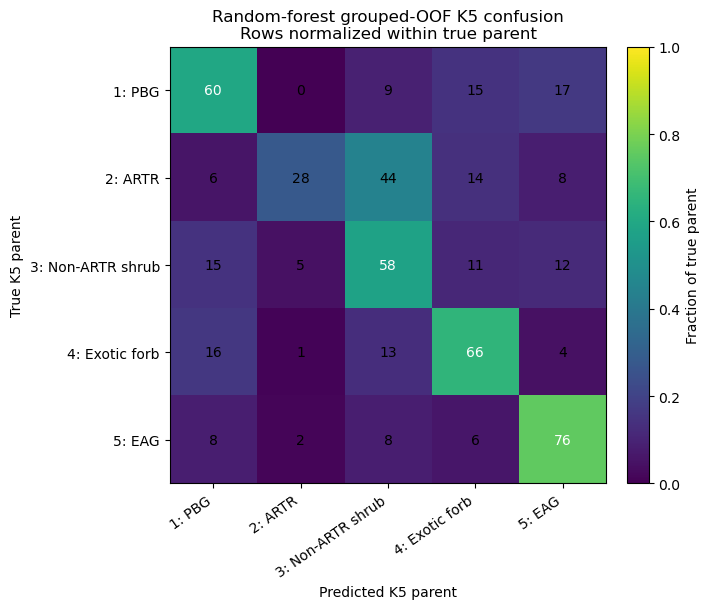

In [9]:
# =============================================================================
# 7B. K5 GROUPED-OOF ACCURACY SUMMARY + ROW-NORMALIZED CONFUSION
# =============================================================================

k5_accuracy_summary = pd.DataFrame(
    [{
        "model": MODEL_FOR_MAPPING,
        "n": len(y),
        "accuracy": accuracy_score(y, rf_pred),
        "balanced_accuracy": balanced_accuracy_score(y, rf_pred),
        "macro_precision": precision_score(
            y,
            rf_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
        "macro_recall": recall_score(
            y,
            rf_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            y,
            rf_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
    }]
)

display(
    k5_accuracy_summary.style
    .format({
        "accuracy": "{:.3f}",
        "balanced_accuracy": "{:.3f}",
        "macro_precision": "{:.3f}",
        "macro_recall": "{:.3f}",
        "macro_f1": "{:.3f}",
    })
    .hide(axis="index")
)

cm_prop = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.2, 6.2))

im = ax.imshow(
    cm_prop,
    vmin=0,
    vmax=1,
    aspect="equal",
    interpolation="nearest",
)

labels_k5 = [
    f"{code}: {K5_LABELS[code]}"
    for code in K5_CODES
]

ax.set_xticks(np.arange(len(K5_CODES)))
ax.set_yticks(np.arange(len(K5_CODES)))
ax.set_xticklabels(labels_k5, rotation=35, ha="right")
ax.set_yticklabels(labels_k5)

ax.set_xlabel("Predicted K5 parent")
ax.set_ylabel("True K5 parent")
ax.set_title(
    "Random-forest grouped-OOF K5 confusion\n"
    "Rows normalized within true parent"
)

for i in range(len(K5_CODES)):
    for j in range(len(K5_CODES)):
        v = cm_prop[i, j]
        ax.text(
            j,
            i,
            f"{100*v:.0f}",
            ha="center",
            va="center",
            fontsize=10,
            color="white" if v >= 0.50 else "black",
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Fraction of true parent")

fig.tight_layout()
plt.show()


## 8. Diagnostic K=24 state accuracy

This section evaluates the species-defined diagnostic subclusters using the **same
raw-plus-ratio IA75 predictor matrix** used for the K5 parent model.

The state response is joined back to the already prepared field observations by
normalized `PlotID × Year`. Zero-species/unassigned observations are excluded because
they do not define one of the 24 diagnostic vegetation states.

Validation remains plot-grouped. The number of folds is reduced only if the rarest
state does not contain five unique plots.


In [10]:
# =============================================================================
# 8A. ATTACH DIAGNOSTIC K24 STATE LABELS TO THE PREPARED ML TABLE
# =============================================================================

if not K24_ASSIGNMENTS_CSV.exists():
    raise FileNotFoundError(K24_ASSIGNMENTS_CSV)

k24 = (
    pd.read_csv(K24_ASSIGNMENTS_CSV, low_memory=False)
    .drop(columns=["Unnamed: 0"], errors="ignore")
)

if "Plot" in k24.columns:
    K24_PLOT_COL = "Plot"
elif "PlotID" in k24.columns:
    K24_PLOT_COL = "PlotID"
else:
    raise KeyError("K24 assignment table must contain Plot or PlotID.")

if "diagnostic_state_id" not in k24.columns:
    raise KeyError(
        "K24 assignment table must contain diagnostic_state_id."
    )

k24["Year"] = pd.to_numeric(k24["Year"], errors="coerce")
k24 = k24.loc[k24["Year"].isin(VEG_YEARS)].copy()
k24["Year"] = k24["Year"].astype(int)
k24["_join_plot"] = k24[K24_PLOT_COL].map(normalize_plot_id)

k24["state_id"] = k24["diagnostic_state_id"].astype("string")
k24 = k24.loc[k24["state_id"].notna()].copy()
k24["state_id"] = k24["state_id"].astype(str)

K24_LABELS = {'1.1': 'AGCR', '1.2': 'POSE', '1.3': 'PBG', '1.4': 'PSSP6', '1.5': 'Mixed/multi', '2.1': 'ARTR + AGCR/CHVI', '2.2': 'ARTR + BRTE', '2.3': 'ARTR + POSE', '2.4': 'ARTR + EF', '3.1': 'Mixed shrub', '3.2': 'CHVI8', '3.3': 'KRLA2', '3.4': 'ATCO', '4.1': 'BAPR5', '4.2': 'SATR12', '4.3': 'BRASS', '4.4': 'LEPE2', '4.5': 'SIAL2', '4.6': 'CETE5', '5.1': 'BRTE/ARTR', '5.2': 'BRTE mono', '5.3': 'BRTE + AGCR', '5.4': 'BRTE + BRASS', '5.5': 'BRTE + POSE'}

K24_CLASSES = sorted(
    K24_LABELS,
    key=lambda x: tuple(int(v) for v in x.split("."))
)

unexpected_k24 = sorted(
    set(k24["state_id"].unique()) - set(K24_CLASSES)
)

if unexpected_k24:
    raise ValueError(
        "Unexpected diagnostic state IDs: "
        + ", ".join(unexpected_k24)
    )

if k24.duplicated(JOIN_KEYS).any():
    dup = k24.loc[
        k24.duplicated(JOIN_KEYS, keep=False),
        [K24_PLOT_COL, "Year", "_join_plot", "state_id"],
    ].head(20)

    raise ValueError(
        "K24 table contains duplicate normalized Plot-Year keys:\n"
        + dup.to_string(index=False)
    )

# veg is already the final modeling table after optional mask filtering.
k24_join = veg[["_join_plot", "Year", "PlotID"]].copy()
k24_join["_row_id"] = np.arange(len(k24_join))

k24_join = k24_join.merge(
    k24[["_join_plot", "Year", "state_id"]],
    on=JOIN_KEYS,
    how="left",
    validate="one_to_one",
)

state_mask = k24_join["state_id"].notna().to_numpy()

print(
    "Prepared K5 modeling rows:",
    len(veg),
)
print(
    "Rows with diagnostic K24 state:",
    int(state_mask.sum()),
)
print(
    "Excluded zero-species/unassigned rows:",
    int((~state_mask).sum()),
)

X_k24 = X_features[state_mask]
y_k24 = k24_join.loc[state_mask, "state_id"].astype(str).to_numpy()
groups_k24 = k24_join.loc[state_mask, "PlotID"].astype(str).to_numpy()

k24_support = (
    pd.DataFrame({
        "state_id": y_k24,
        "PlotID": groups_k24,
    })
    .groupby("state_id")
    .agg(
        n=("PlotID", "size"),
        n_plots=("PlotID", "nunique"),
    )
    .reindex(K24_CLASSES)
    .reset_index()
)

k24_support["state_label"] = k24_support["state_id"].map(K24_LABELS)

display(k24_support)


Prepared K5 modeling rows: 479
Rows with diagnostic K24 state: 476
Excluded zero-species/unassigned rows: 3


,state_id,n,n_plots,state_label
0,1.1,32.0,30.0,AGCR
1,1.2,52.0,50.0,POSE
2,1.3,6.0,6.0,PBG
3,1.4,8.0,8.0,PSSP6
4,1.5,11.0,10.0,Mixed/multi
5,2.1,NaN,NaN,ARTR + AGCR/CHVI
6,2.2,14.0,14.0,ARTR + BRTE
7,2.3,9.0,9.0,ARTR + POSE
8,2.4,13.0,13.0,ARTR + EF
9,3.1,25.0,25.0,Mixed shrub


In [11]:
# =============================================================================
# 8B. GROUPED OOF VALIDATION — 24 DIAGNOSTIC STATES
# =============================================================================

min_k24_groups = int(k24_support["n_plots"].min())
K24_N_SPLITS = min(N_SPLITS, min_k24_groups)

if K24_N_SPLITS < 2:
    raise ValueError(
        "At least one diagnostic state has fewer than two unique PlotIDs; "
        "grouped OOF evaluation is not possible for all 24 states."
    )

print("K24 grouped CV folds:", K24_N_SPLITS)
print("Minimum unique plots/state:", min_k24_groups)

k24_cv = StratifiedGroupKFold(
    n_splits=K24_N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

K24_CV_SPLITS = list(
    k24_cv.split(
        X_k24,
        y_k24,
        groups_k24,
    )
)

k24_oof_predictions = {}
k24_fold_rows = []

for model_name, template in MODELS.items():
    pred_all = np.empty(len(y_k24), dtype=object)
    pred_all[:] = None

    for fold, (train_idx, test_idx) in enumerate(
        K24_CV_SPLITS,
        start=1,
    ):
        fitted = clone(template)

        fitted.fit(
            X_k24[train_idx],
            y_k24[train_idx],
        )

        pred = fitted.predict(
            X_k24[test_idx]
        ).astype(str)

        pred_all[test_idx] = pred

        k24_fold_rows.append(
            {
                "model": model_name,
                "fold": fold,
                "n_train": len(train_idx),
                "n_test": len(test_idx),
                "accuracy": accuracy_score(
                    y_k24[test_idx],
                    pred,
                ),
                "balanced_accuracy": balanced_accuracy_score(
                    y_k24[test_idx],
                    pred,
                ),
                "macro_precision": precision_score(
                    y_k24[test_idx],
                    pred,
                    labels=K24_CLASSES,
                    average="macro",
                    zero_division=0,
                ),
                "macro_recall": recall_score(
                    y_k24[test_idx],
                    pred,
                    labels=K24_CLASSES,
                    average="macro",
                    zero_division=0,
                ),
                "macro_f1": f1_score(
                    y_k24[test_idx],
                    pred,
                    labels=K24_CLASSES,
                    average="macro",
                    zero_division=0,
                ),
            }
        )

    k24_oof_predictions[model_name] = pred_all

k24_pooled_rows = []

for model_name, pred in k24_oof_predictions.items():
    k24_pooled_rows.append(
        {
            "model": model_name,
            "n": len(y_k24),
            "accuracy": accuracy_score(y_k24, pred),
            "balanced_accuracy": balanced_accuracy_score(y_k24, pred),
            "macro_precision": precision_score(
                y_k24,
                pred,
                labels=K24_CLASSES,
                average="macro",
                zero_division=0,
            ),
            "macro_recall": recall_score(
                y_k24,
                pred,
                labels=K24_CLASSES,
                average="macro",
                zero_division=0,
            ),
            "macro_f1": f1_score(
                y_k24,
                pred,
                labels=K24_CLASSES,
                average="macro",
                zero_division=0,
            ),
        }
    )

k24_fold_metrics = pd.DataFrame(k24_fold_rows)
k24_pooled = pd.DataFrame(k24_pooled_rows)

print("K24 pooled grouped-OOF metrics:")
display(
    k24_pooled
    .sort_values("macro_f1", ascending=False)
    .round(4)
)

print("\nK24 fold variability:")
display(
    k24_fold_metrics.groupby("model")[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)


K24 grouped CV folds: 5
Minimum unique plots/state: 5


c:\Users\scottfordham\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\scottfordham\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\scottfordham\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\scottfordham\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\scottfordham\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in

K24 pooled grouped-OOF metrics:


c:\Users\scottfordham\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,model,n,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
2,extra_trees,476,0.3655,0.2817,0.2505,0.2582,0.2502
1,random_forest,476,0.3697,0.2588,0.2417,0.2372,0.2373
0,elastic_net_logistic,476,0.2752,0.2530,0.2149,0.2320,0.2122



K24 fold variability:


accuracy                      balanced_accuracy                      macro_f1                     
                         mean    std    min    max              mean    std    min    max     mean    std    min    max
model                                                                                                                  
elastic_net_logistic    0.276  0.061  0.216  0.356             0.244  0.074  0.164  0.325    0.188  0.050  0.145  0.247
extra_trees             0.367  0.041  0.340  0.437             0.297  0.039  0.268  0.364    0.227  0.039  0.188  0.290
random_forest           0.370  0.048  0.289  0.402             0.269  0.049  0.189  0.317    0.215  0.042  0.152  0.262

state_id,state_label,precision,recall,f1,support
1.1,AGCR,0.308,0.375,0.338,32
1.2,POSE,0.424,0.538,0.475,52
1.3,PBG,0.000,0.000,0.000,6
1.4,PSSP6,0.143,0.125,0.133,8
1.5,Mixed/multi,0.143,0.091,0.111,11
2.1,ARTR + AGCR/CHVI,0.000,0.000,0.000,0
2.2,ARTR + BRTE,0.000,0.000,0.000,14
2.3,ARTR + POSE,0.222,0.222,0.222,9
2.4,ARTR + EF,0.250,0.231,0.240,13
3.1,Mixed shrub,0.318,0.280,0.298,25


C:\Users\scottfordham\AppData\Local\Temp\ipykernel_31060\3024246711.py:52: RuntimeWarning: invalid value encountered in divide
  k24_cm_prop = k24_cm / k24_cm.sum(axis=1, keepdims=True)


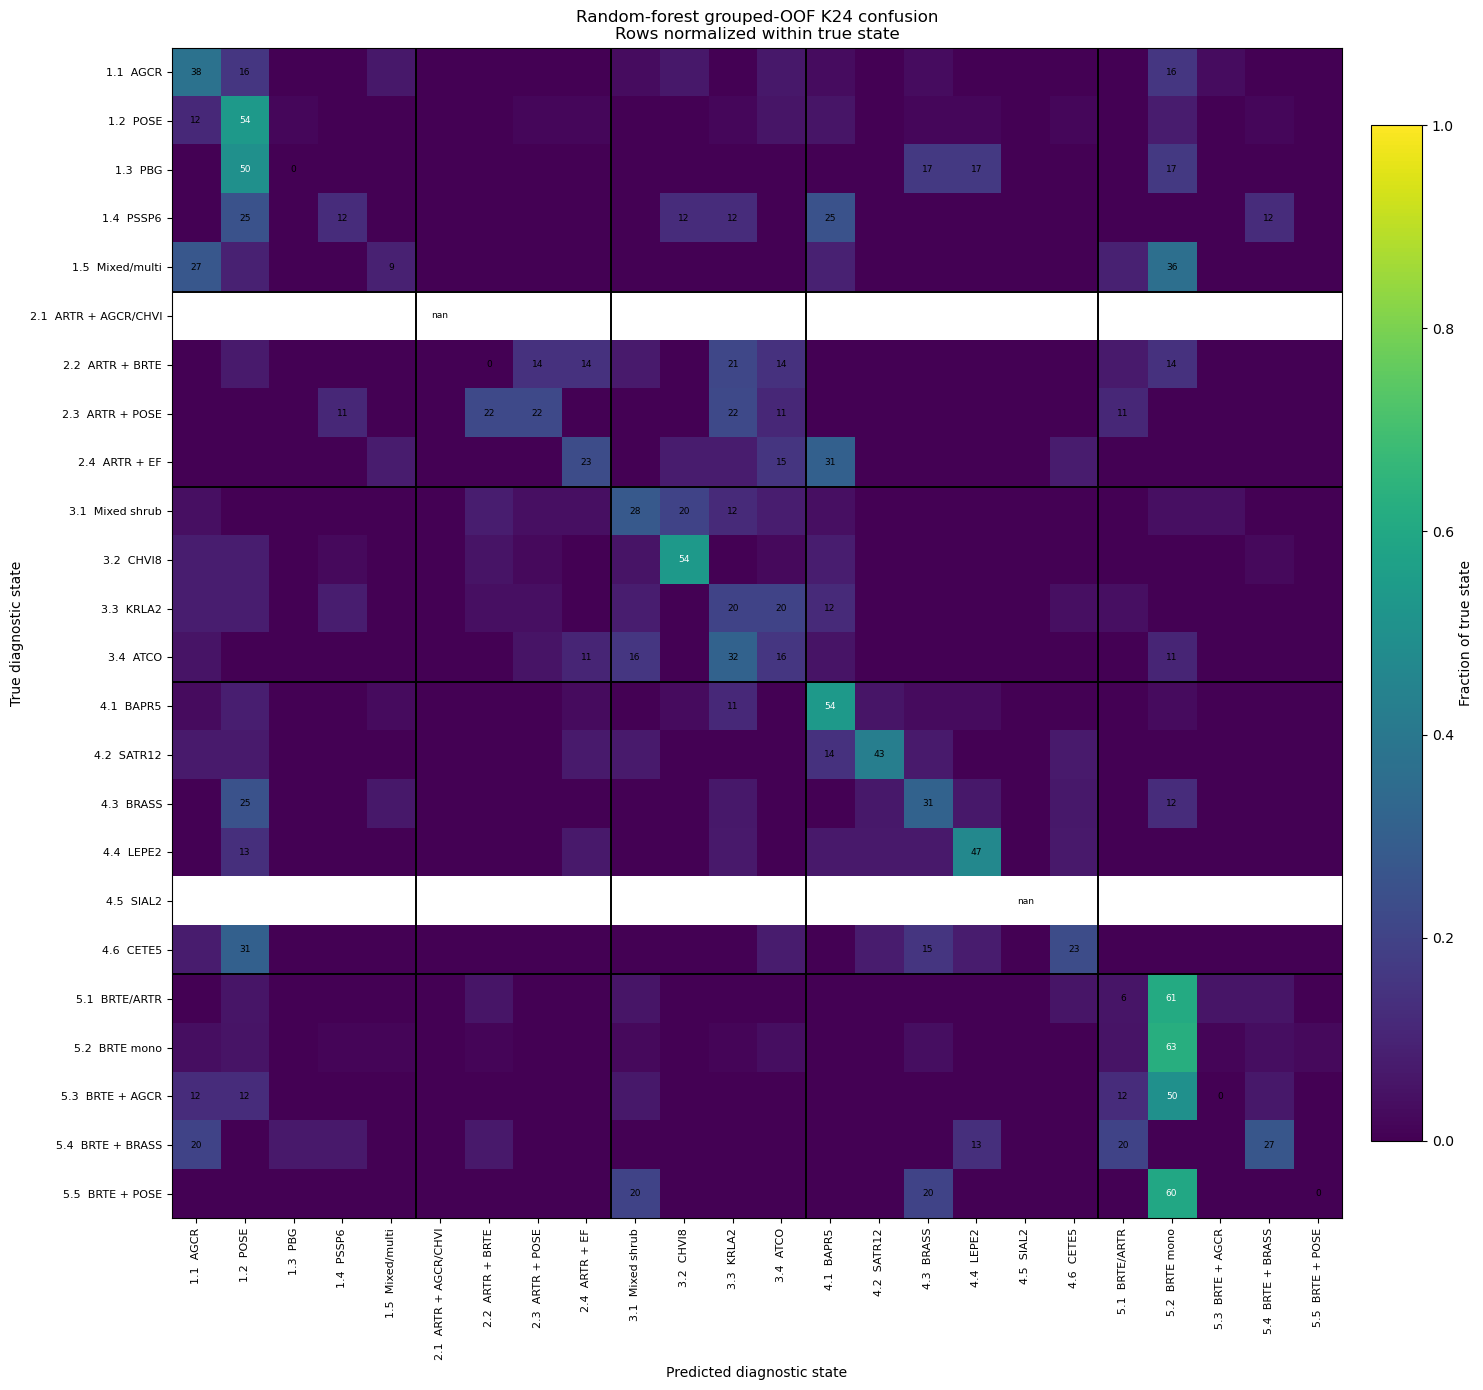

In [12]:
# =============================================================================
# 8C. K24 RANDOM-FOREST CLASSWISE PERFORMANCE + CONFUSION MATRIX
# =============================================================================

k24_rf_pred = np.asarray(
    k24_oof_predictions[MODEL_FOR_MAPPING],
    dtype=str,
)

k24_report = classification_report(
    y_k24,
    k24_rf_pred,
    labels=K24_CLASSES,
    output_dict=True,
    zero_division=0,
)

k24_classwise_rows = []

for state_id in K24_CLASSES:
    r = k24_report[state_id]

    k24_classwise_rows.append(
        {
            "state_id": state_id,
            "state_label": K24_LABELS[state_id],
            "precision": r["precision"],
            "recall": r["recall"],
            "f1": r["f1-score"],
            "support": int(r["support"]),
        }
    )

k24_classwise = pd.DataFrame(k24_classwise_rows)

display(
    k24_classwise.style
    .format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1": "{:.3f}",
    })
    .hide(axis="index")
)

k24_cm = confusion_matrix(
    y_k24,
    k24_rf_pred,
    labels=K24_CLASSES,
)

k24_cm_prop = k24_cm / k24_cm.sum(axis=1, keepdims=True)

k24_display = [
    f"{sid}  {K24_LABELS[sid]}"
    for sid in K24_CLASSES
]

fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(
    k24_cm_prop,
    vmin=0,
    vmax=1,
    aspect="equal",
    interpolation="nearest",
)

ax.set_xticks(np.arange(len(K24_CLASSES)))
ax.set_yticks(np.arange(len(K24_CLASSES)))
ax.set_xticklabels(k24_display, rotation=90, fontsize=8)
ax.set_yticklabels(k24_display, fontsize=8)

ax.set_xlabel("Predicted diagnostic state")
ax.set_ylabel("True diagnostic state")
ax.set_title(
    "Random-forest grouped-OOF K24 confusion\n"
    "Rows normalized within true state"
)

for i in range(len(K24_CLASSES)):
    for j in range(len(K24_CLASSES)):
        v = k24_cm_prop[i, j]

        if i == j or v >= 0.10:
            ax.text(
                j,
                i,
                f"{100*v:.0f}",
                ha="center",
                va="center",
                fontsize=6.5,
                color="white" if v >= 0.50 else "black",
            )

parent_codes_k24 = [
    int(s.split(".")[0])
    for s in K24_CLASSES
]

for k in range(1, len(parent_codes_k24)):
    if parent_codes_k24[k] != parent_codes_k24[k - 1]:
        boundary = k - 0.5
        ax.axhline(boundary, color="black", linewidth=1.4)
        ax.axvline(boundary, color="black", linewidth=1.4)

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Fraction of true state")

fig.tight_layout()
plt.show()


resolution,n,accuracy,balanced_accuracy,macro_f1
K5 parents,479,0.624,0.573,0.581
K24 diagnostic states,476,0.370,0.259,0.237


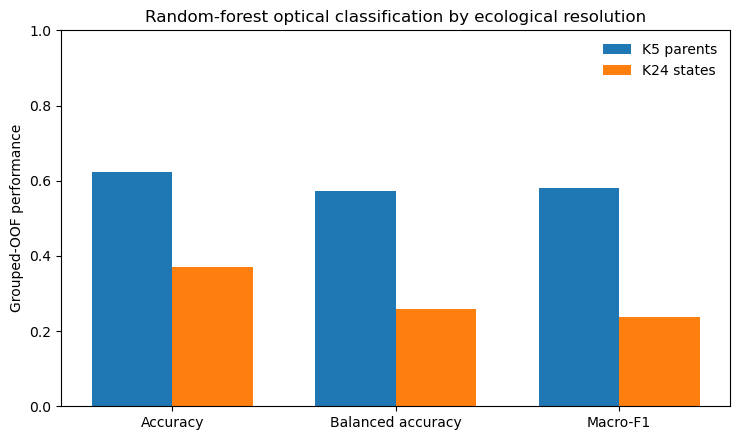

In [13]:
# =============================================================================
# 8D. DIRECT K5 VS K24 RANDOM-FOREST ACCURACY COMPARISON
# =============================================================================

k5_focus = k5_accuracy_summary.iloc[0]
k24_focus = k24_pooled.loc[
    k24_pooled["model"].eq(MODEL_FOR_MAPPING)
].iloc[0]

resolution_comparison = pd.DataFrame(
    [
        {
            "resolution": "K5 parents",
            "n": int(k5_focus["n"]),
            "accuracy": k5_focus["accuracy"],
            "balanced_accuracy": k5_focus["balanced_accuracy"],
            "macro_f1": k5_focus["macro_f1"],
        },
        {
            "resolution": "K24 diagnostic states",
            "n": int(k24_focus["n"]),
            "accuracy": k24_focus["accuracy"],
            "balanced_accuracy": k24_focus["balanced_accuracy"],
            "macro_f1": k24_focus["macro_f1"],
        },
    ]
)

display(
    resolution_comparison.style
    .format({
        "accuracy": "{:.3f}",
        "balanced_accuracy": "{:.3f}",
        "macro_f1": "{:.3f}",
    })
    .hide(axis="index")
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))

metrics = ["accuracy", "balanced_accuracy", "macro_f1"]
x = np.arange(len(metrics))
width = 0.36

k5_vals = [k5_focus[m] for m in metrics]
k24_vals = [k24_focus[m] for m in metrics]

ax.bar(
    x - width / 2,
    k5_vals,
    width,
    label="K5 parents",
)

ax.bar(
    x + width / 2,
    k24_vals,
    width,
    label="K24 states",
)

ax.set_xticks(x)
ax.set_xticklabels([
    "Accuracy",
    "Balanced accuracy",
    "Macro-F1",
])
ax.set_ylim(0, 1)
ax.set_ylabel("Grouped-OOF performance")
ax.set_title(
    "Random-forest optical classification by ecological resolution"
)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()


## 10. Leave-one-year-out temporal transfer

For each monitored year, every vegetation label from that year is withheld during fitting. The target-year S500 optical normalization remains available because it is estimated from unlabeled imagery, not vegetation labels.


In [14]:
# =============================================================================
# 10. LEAVE-ONE-YEAR-OUT
# =============================================================================

loyo_rows = []
loyo_confusion_rows = []

for model_name, template in MODELS.items():
    for held_year in VEG_YEARS:
        train_mask = years_veg != held_year
        test_mask = years_veg == held_year

        fitted = clone(template)

        fitted.fit(
            X_features[train_mask],
            y[train_mask],
        )

        pred = fitted.predict(
            X_features[test_mask]
        ).astype(str)

        loyo_rows.append(
            {
                "model": model_name,
                "held_out_year": held_year,
                "n_train": int(train_mask.sum()),
                "n_test": int(test_mask.sum()),
                **score_predictions(
                    y[test_mask],
                    pred,
                ),
            }
        )

        cm = confusion_matrix(
            y[test_mask],
            pred,
            labels=VEG_CLASSES,
        )

        for true_i, true_code in enumerate(K5_CODES):
            for pred_i, pred_code in enumerate(K5_CODES):
                loyo_confusion_rows.append(
                    {
                        "model": model_name,
                        "held_out_year": held_year,
                        "true_code": true_code,
                        "true_label": K5_LABELS[true_code],
                        "predicted_code": pred_code,
                        "predicted_label": K5_LABELS[pred_code],
                        "n": int(cm[true_i, pred_i]),
                    }
                )


loyo_df = pd.DataFrame(loyo_rows)
loyo_confusion_df = pd.DataFrame(loyo_confusion_rows)

loyo_df.to_csv(
    OUTPUT_DIR / "K5_RawPlusRatios_leaveYearOut.csv",
    index=False,
)

loyo_confusion_df.to_csv(
    OUTPUT_DIR / "K5_RawPlusRatios_leaveYearOut_confusion_long.csv",
    index=False,
)

print("Leave-one-year-out metrics:")
display(
    loyo_df.sort_values(
        ["held_out_year", "model"],
    ).round(4)
)


NameError: name 'years_veg' is not defined

## 10. Save the explicit K5 relative-harmonic modeling dataset

The 75 predictors are beta0, A1, A2, A1/beta0, and A2/A1 for each of 15 variables. No annual z-scores are used.


In [16]:
# =============================================================================
# 10. SAVE MODELING DATASET
# =============================================================================

modeling_dataset = veg[
    [
        c
        for c in [
            "PlotID",
            "Year",
            "parent_cluster_k5",
            "k5_label",
            "Easting",
            "Northing",
            "max_membership_k5",
            "membership_margin_k5",
        ]
        if c in veg.columns
    ]
].copy()

for j, feature in enumerate(FEATURE_NAMES):
    modeling_dataset[feature] = X_features[:, j]

MODELING_DATASET_PATH = (
    OUTPUT_DIR
    / "FieldVeg_K5_RawPlusRatios_IA75_modeling_dataset.csv"
)

modeling_dataset.to_csv(
    MODELING_DATASET_PATH,
    index=False,
)

print("Wrote:", MODELING_DATASET_PATH)
print("Rows:", len(modeling_dataset))


Wrote: C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA75_K5\FieldVeg_K5_RawPlusRatios_IA75_modeling_dataset.csv
Rows: 479


## 11. Fit the final random-forest mapping model

This model uses all matched monitored observations. The raster maps are therefore production predictions from the full training set; the OOF and LOYO results above are the held-out validation results.


In [17]:
# =============================================================================
# 11. FINAL MAPPING MODEL
# =============================================================================

mapping_model = clone(
    MODELS[MODEL_FOR_MAPPING]
)

t0 = time.perf_counter()

mapping_model.fit(
    X_features,
    y,
)

print("Mapping model:", MODEL_FOR_MAPPING)
print("Training rows:", len(veg))
print("Classes:", mapping_model.classes_)
print(
    "Fit time:",
    f"{(time.perf_counter() - t0) / 60:.2f} min",
)


Mapping model: random_forest
Training rows: 479
Classes: ['K5::1' 'K5::2' 'K5::3' 'K5::4' 'K5::5']
Fit time: 0.01 min


## 12. Raster helpers and annual blockwise mapping

Class raster codes are the K5 labels directly:

1. PBG
2. ARTR
3. Non-ARTR shrub
4. Exotic forb
5. EAG

Uncertainty raster bands are relative model diagnostics: maximum class probability, top-two probability margin, and prediction entropy.


In [18]:
# =============================================================================
# 12. RASTER HELPERS — SOURCE IA BAND MATCHING
# =============================================================================

def annual_k2_path(year):
    return (HARMONIC_ROOT / str(year) / f"{year}_K2_InterceptAmpPhase_nobs_RMSE.tif")


def get_band_names(src):
    return [
        str(desc).strip() if desc is not None and str(desc).strip() else f"band_{i}"
        for i, desc in enumerate(src.descriptions, start=1)
    ]


def ia_band_indexes(src, feature_names):
    lookup = {normalize_feature_name(name): i for i, name in enumerate(get_band_names(src), start=1)}
    missing = [feature for feature in feature_names if normalize_feature_name(feature) not in lookup]
    if missing:
        raise KeyError("Missing annual raster IA bands:\n" + "\n".join(missing))
    return [lookup[normalize_feature_name(feature)] for feature in feature_names]


def grids_match(src_a, src_b):
    return (src_a.width == src_b.width and src_a.height == src_b.height
            and src_a.transform == src_b.transform and src_a.crs == src_b.crs)


def predictive_entropy(proba):
    eps = 1e-12
    return -np.sum(proba * np.log(np.maximum(proba, eps)), axis=1)


for year in YEARS_TO_MAP:
    path = annual_k2_path(year)
    if not path.exists():
        raise FileNotFoundError(f"Missing annual harmonic raster:\n{path}")
    with rasterio.open(path) as src:
        indexes = ia_band_indexes(src, SOURCE_IA_COLS)
    print(year, "| aligned original IA:", len(indexes))


2016 | aligned original IA: 45
2017 | aligned original IA: 45
2018 | aligned original IA: 45
2019 | aligned original IA: 45
2020 | aligned original IA: 45
2021 | aligned original IA: 45
2022 | aligned original IA: 45
2023 | aligned original IA: 45
2024 | aligned original IA: 45
2025 | aligned original IA: 45


In [19]:
# =============================================================================
# 13. BLOCKWISE K5 MAPPING FUNCTION
# =============================================================================


def classify_year_relative_k5(
    year,
    model,
):
    src_path = annual_k2_path(year)

    class_path = (
        OUTPUT_DIR
        / f"K5_RawPlusRatios_{MODEL_FOR_MAPPING}_{year}_class.tif"
    )

    uncertainty_path = (
        OUTPUT_DIR
        / f"K5_RawPlusRatios_{MODEL_FOR_MAPPING}_{year}_uncertainty.tif"
    )

    if not ALLOW_OVERWRITE:
        existing = [
            p
            for p in [class_path, uncertainty_path]
            if p.exists()
        ]

        if existing:
            raise FileExistsError(
                "Refusing to overwrite existing K5 raster outputs:\n"
                + "\n".join(str(p) for p in existing)
            )

    print("\n" + "=" * 100)
    print(f"CLASSIFYING {year} — K5 RAW + RATIO IA75")
    print("=" * 100)

    year_start = time.perf_counter()

    with rasterio.open(src_path) as src, rasterio.open(KEEP_MASK) as mask_src:
        indexes = ia_band_indexes(
            src,
            SOURCE_IA_COLS,
        )

        use_direct_mask = grids_match(
            src,
            mask_src,
        )

        mask_vrt = None

        if not use_direct_mask:
            mask_vrt = WarpedVRT(
                mask_src,
                crs=src.crs,
                transform=src.transform,
                width=src.width,
                height=src.height,
                resampling=Resampling.nearest,
            )

        blocks = list(
            src.block_windows(1)
        )

        n_blocks = len(blocks)

        class_profile = src.profile.copy()
        class_profile.update(
            driver="GTiff",
            count=1,
            dtype="uint8",
            nodata=0,
            compress=COMPRESS,
            tiled=True,
            BIGTIFF="IF_SAFER",
        )

        uncertainty_profile = src.profile.copy()
        uncertainty_profile.update(
            driver="GTiff",
            count=3,
            dtype="float32",
            nodata=-9999.0,
            compress=COMPRESS,
            predictor=3,
            tiled=True,
            BIGTIFF="IF_SAFER",
        )

        model_classes = np.asarray(
            model.classes_,
            dtype=object,
        )

        total_valid = 0

        with rasterio.open(
            class_path,
            "w",
            **class_profile,
        ) as class_dst, rasterio.open(
            uncertainty_path,
            "w",
            **uncertainty_profile,
        ) as uncertainty_dst:

            class_dst.set_band_description(
                1,
                "predicted_k5_vegetation_class",
            )

            uncertainty_dst.set_band_description(1, "max_probability")
            uncertainty_dst.set_band_description(2, "probability_margin")
            uncertainty_dst.set_band_description(3, "prediction_entropy")

            for block_number, (_, window) in enumerate(
                blocks,
                start=1,
            ):
                if use_direct_mask:
                    keep = mask_src.read(
                        1,
                        window=window,
                        masked=False,
                    )
                else:
                    keep = mask_vrt.read(
                        1,
                        window=window,
                        masked=False,
                    )

                keep_valid = (
                    np.isfinite(keep)
                    & (keep > 0)
                )

                features = src.read(
                    indexes,
                    window=window,
                    masked=False,
                ).astype(
                    np.float32,
                    copy=False,
                )

                features = np.moveaxis(
                    features,
                    0,
                    -1,
                )

                valid = (
                    keep_valid
                    & np.isfinite(features).all(axis=2)
                )

                if src.nodata is not None:
                    valid &= ~np.any(
                        np.isclose(
                            features,
                            src.nodata,
                        ),
                        axis=2,
                    )

                # Denominator validity must match the field-data preparation.
                candidate_rows = np.flatnonzero(valid.ravel())
                if len(candidate_rows):
                    X_candidates = features.reshape(-1, SOURCE_D)[candidate_rows]
                    _, ratios_ok = transform_raw_plus_ratios(X_candidates)
                    valid.ravel()[candidate_rows[~ratios_ok]] = False

                n_valid = int(valid.sum())
                total_valid += n_valid

                class_block = np.zeros(
                    (
                        int(window.height),
                        int(window.width),
                    ),
                    dtype=np.uint8,
                )

                uncertainty_block = np.full(
                    (
                        3,
                        int(window.height),
                        int(window.width),
                    ),
                    -9999.0,
                    dtype=np.float32,
                )

                if n_valid > 0:
                    X_block_raw = features[valid]
                    X_block_rel, all_valid = transform_raw_plus_ratios(X_block_raw)
                    if not all_valid.all():
                        raise RuntimeError("Internal ratio-validity mask mismatch")

                    proba = model.predict_proba(
                        X_block_rel
                    ).astype(
                        np.float32,
                        copy=False,
                    )

                    winner_idx = np.argmax(
                        proba,
                        axis=1,
                    )

                    winner_class = model_classes[winner_idx]

                    winner_code = np.fromiter(
                        (
                            CLASS_TO_CODE[str(cls)]
                            for cls in winner_class
                        ),
                        dtype=np.uint8,
                        count=len(winner_class),
                    )

                    class_block[valid] = winner_code

                    sorted_p = np.sort(
                        proba,
                        axis=1,
                    )

                    max_p = sorted_p[:, -1]
                    margin = (
                        sorted_p[:, -1]
                        - sorted_p[:, -2]
                    )
                    entropy = predictive_entropy(proba)

                    uncertainty_block[0][valid] = max_p
                    uncertainty_block[1][valid] = margin
                    uncertainty_block[2][valid] = entropy.astype(np.float32)

                class_dst.write(
                    class_block,
                    1,
                    window=window,
                )

                uncertainty_dst.write(
                    uncertainty_block,
                    window=window,
                )

                if (
                    block_number == 1
                    or block_number % 25 == 0
                    or block_number == n_blocks
                ):
                    elapsed = time.perf_counter() - year_start
                    rate = block_number / elapsed if elapsed > 0 else np.nan
                    eta = (
                        (n_blocks - block_number) / rate
                        if rate > 0
                        else np.nan
                    )

                    print(
                        f"{year} | {block_number:,}/{n_blocks:,} "
                        f"({100 * block_number / n_blocks:5.1f}%) | "
                        f"elapsed {elapsed / 60:6.1f} min | "
                        f"ETA {eta / 60:6.1f} min | "
                        f"classified {total_valid:,} px"
                    )

        if mask_vrt is not None:
            mask_vrt.close()

    runtime = (
        time.perf_counter()
        - year_start
    ) / 60.0

    print(f"{year} complete in {runtime:.1f} min")

    return {
        "Year": year,
        "runtime_minutes": runtime,
        "classified_pixels": total_valid,
        "class_path": str(class_path),
        "uncertainty_path": str(uncertainty_path),
    }


## 14. Run annual mapping (optional)

`RUN_ALL_YEAR_MAPPING` is `False` by default. After the grouped-OOF and LOYO results look reasonable, set it to `True` in the configuration cell and rerun the notebook.


In [23]:
# =============================================================================
# 14. RUN ALL-YEAR MAPPING
# =============================================================================

map_results = []

if RUN_MAPPING:
    all_start = time.perf_counter()

    for year in YEARS_TO_MAP:
        result = classify_year_relative_k5(
            year,
            mapping_model,
        )

        map_results.append(result)

        pd.DataFrame(map_results).to_csv(
            OUTPUT_DIR / "K5_RawPlusRatios_mapping_progress.csv",
            index=False,
        )

    map_results = pd.DataFrame(map_results)

    map_results.to_csv(
        OUTPUT_DIR / "K5_RawPlusRatios_allYears_outputs.csv",
        index=False,
    )

    display(map_results)

    print(
        "Total mapping runtime:",
        f"{(time.perf_counter() - all_start) / 60:.1f} min",
    )

else:
    print(
        "RUN_MAPPING is False; validation/model fitting completed without raster mapping."
    )



CLASSIFYING 2016 — K5 RAW + RATIO IA75
2016 | 1/336 (  0.3%) | elapsed    0.0 min | ETA    2.3 min | classified 0 px
2016 | 25/336 (  7.4%) | elapsed    0.2 min | ETA    2.1 min | classified 314,711 px
2016 | 50/336 ( 14.9%) | elapsed    0.6 min | ETA    3.5 min | classified 2,450,378 px
2016 | 75/336 ( 22.3%) | elapsed    1.1 min | ETA    3.9 min | classified 5,037,742 px
2016 | 100/336 ( 29.8%) | elapsed    1.7 min | ETA    4.0 min | classified 7,955,394 px
2016 | 125/336 ( 37.2%) | elapsed    2.3 min | ETA    4.0 min | classified 11,332,351 px
2016 | 150/336 ( 44.6%) | elapsed    3.2 min | ETA    3.9 min | classified 15,734,439 px
2016 | 175/336 ( 52.1%) | elapsed    4.1 min | ETA    3.8 min | classified 20,715,882 px
2016 | 200/336 ( 59.5%) | elapsed    4.9 min | ETA    3.4 min | classified 25,116,642 px
2016 | 225/336 ( 67.0%) | elapsed    5.6 min | ETA    2.8 min | classified 28,317,958 px
2016 | 250/336 ( 74.4%) | elapsed    6.1 min | ETA    2.1 min | classified 30,696,463 px
2

,Year,runtime_minutes,classified_pixels,class_path,uncertainty_path
0,2016,7.189625,34838847,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
1,2017,7.437368,34930118,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
2,2018,7.284458,34937484,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
3,2019,6.846567,34952320,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
4,2020,7.692237,34973049,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
5,2021,7.577931,34967117,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
6,2022,7.560728,34961885,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
7,2023,7.464755,34975397,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
8,2024,7.468129,34976425,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...
9,2025,7.409662,34961213,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...,C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA...


Total mapping runtime: 73.9 min


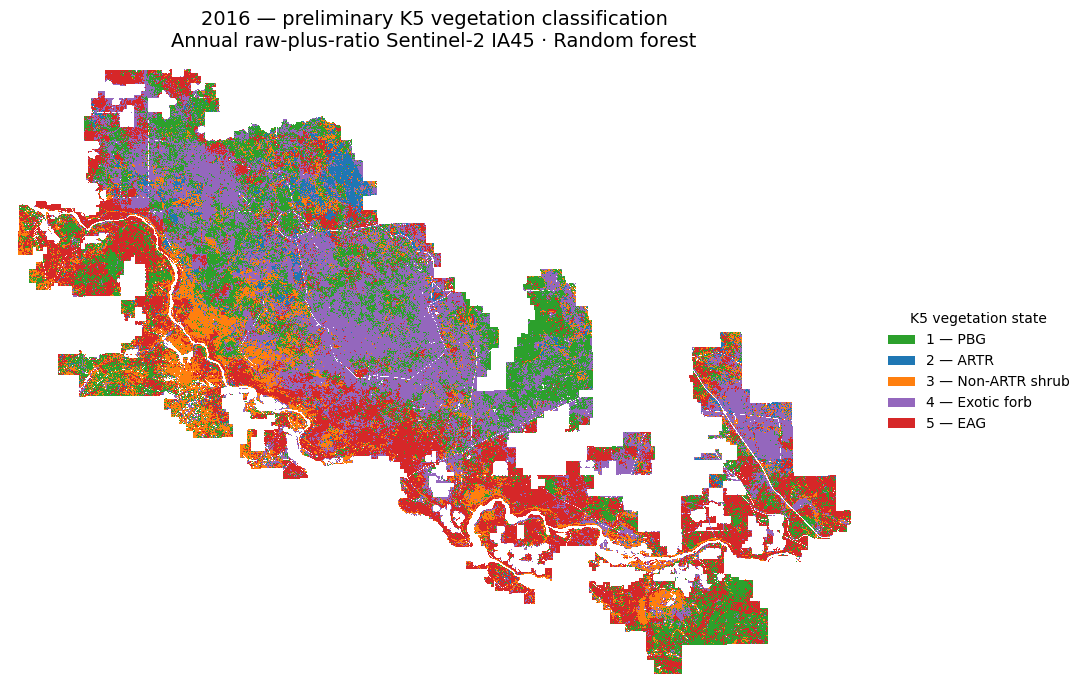

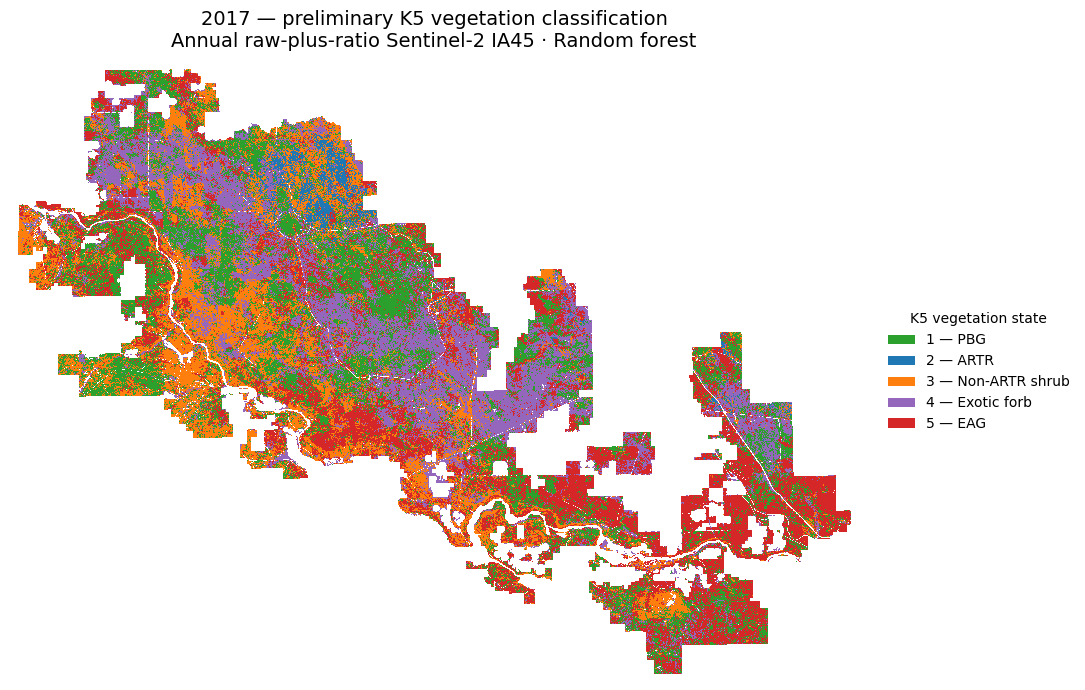

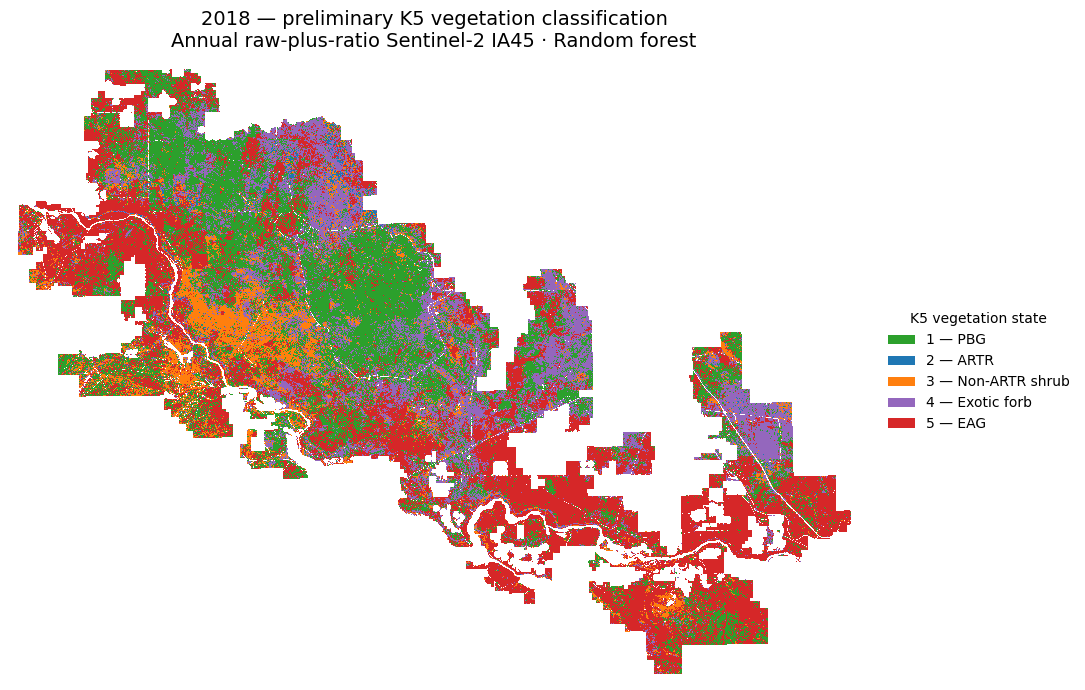

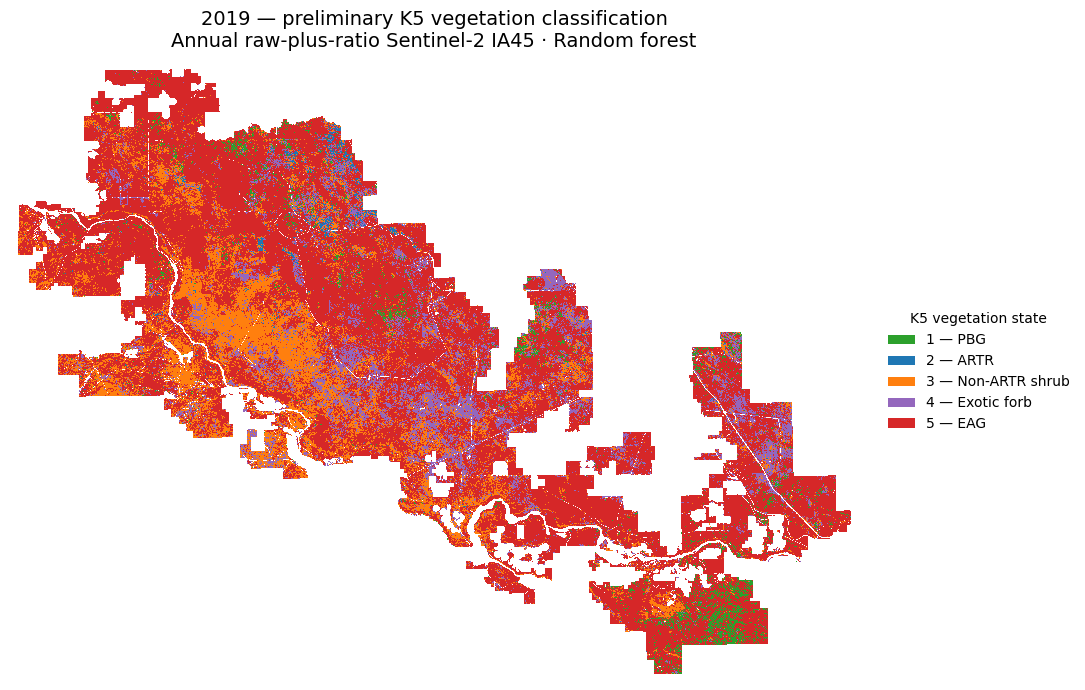

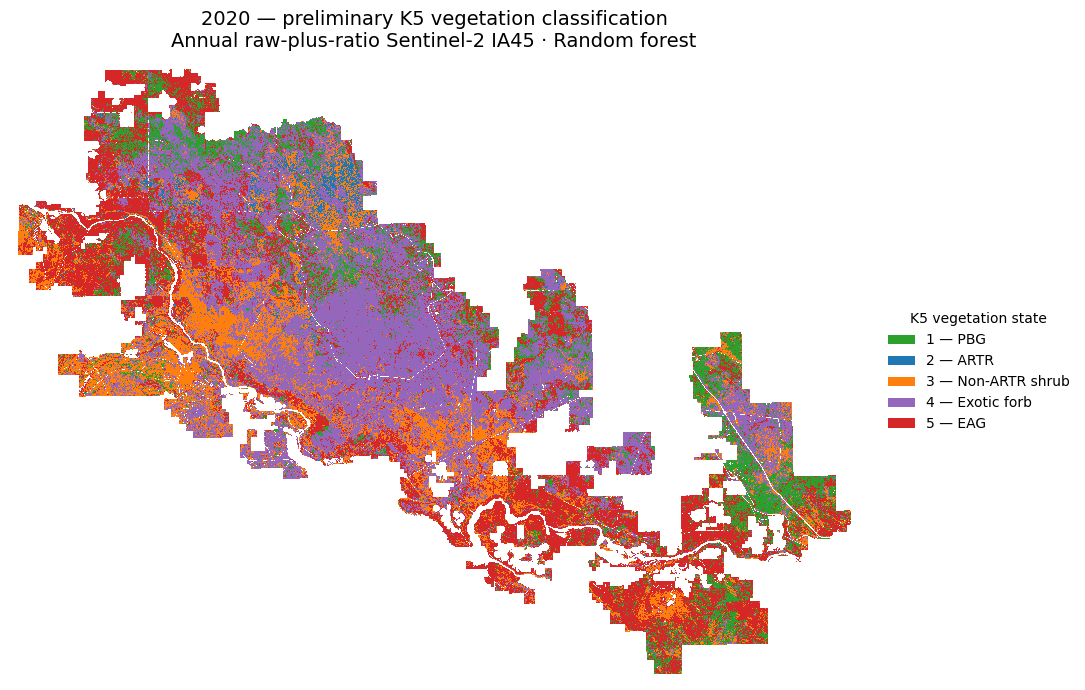

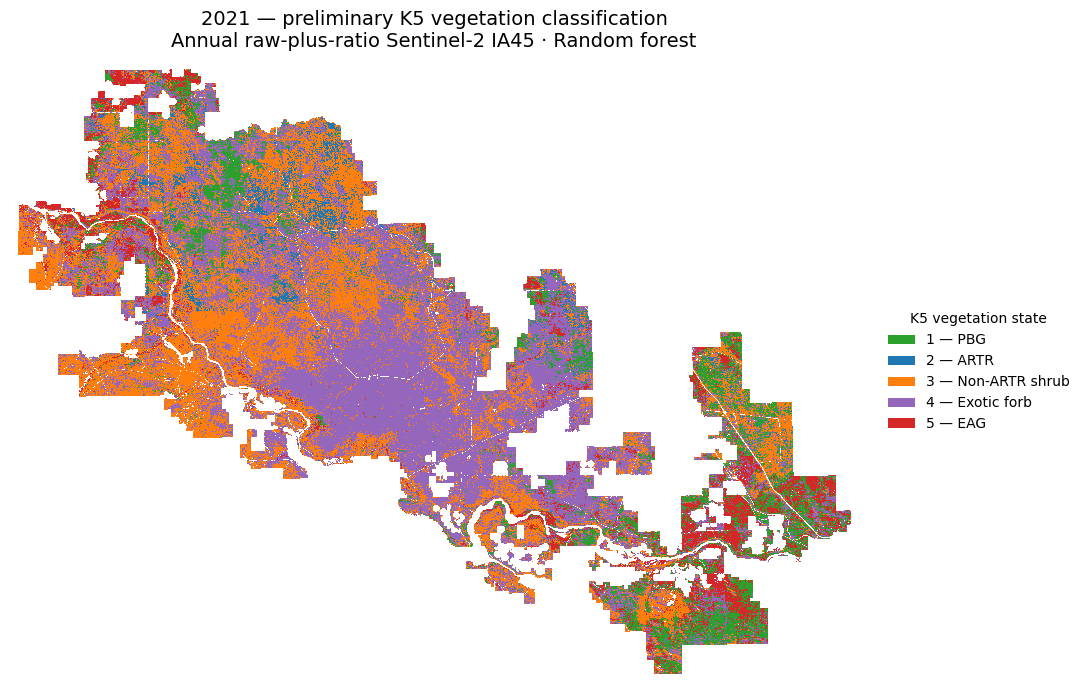

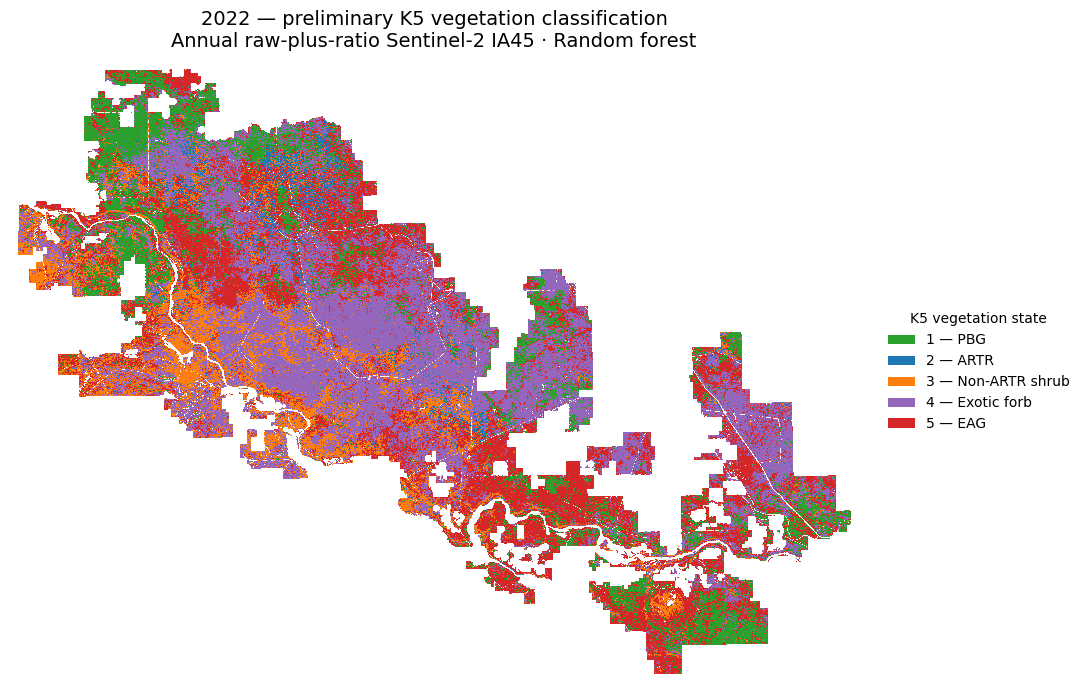

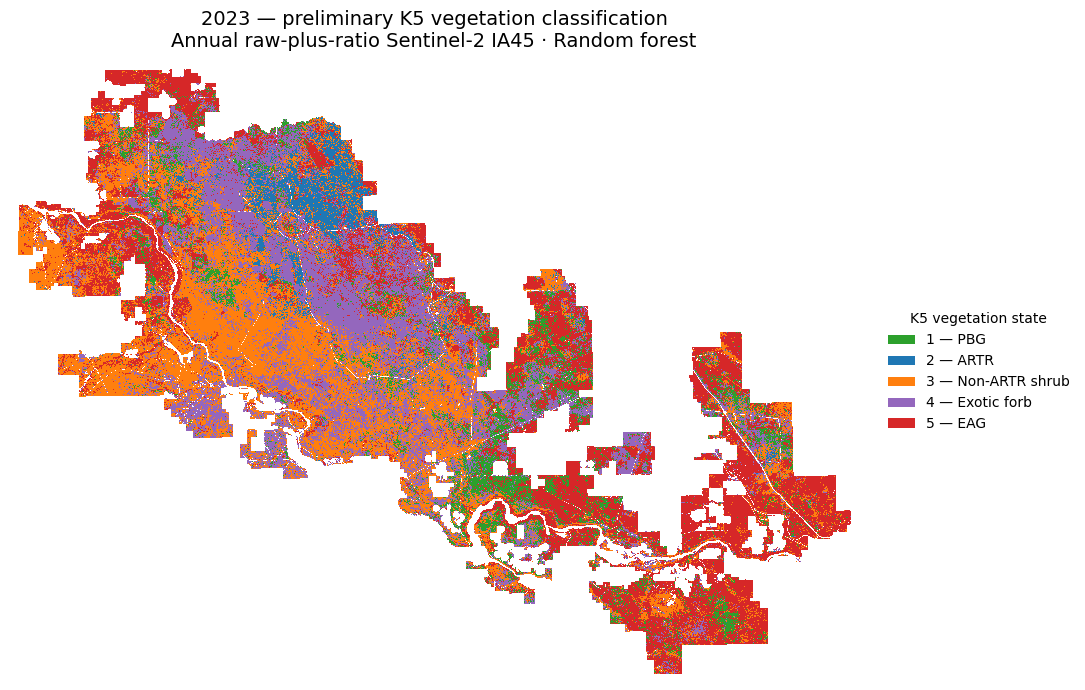

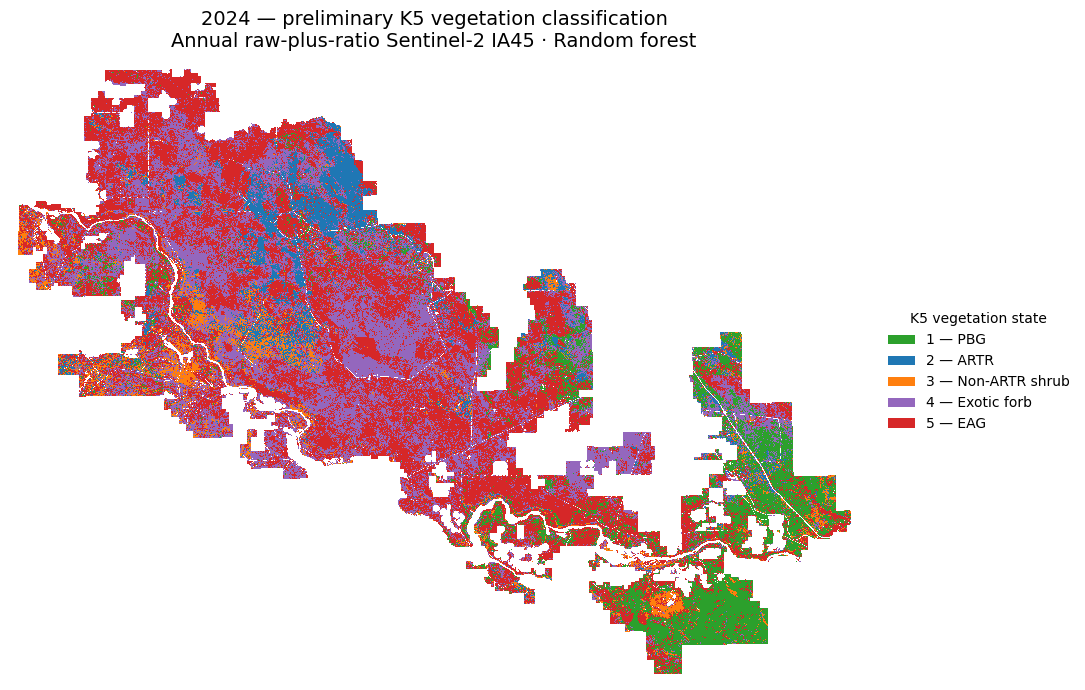

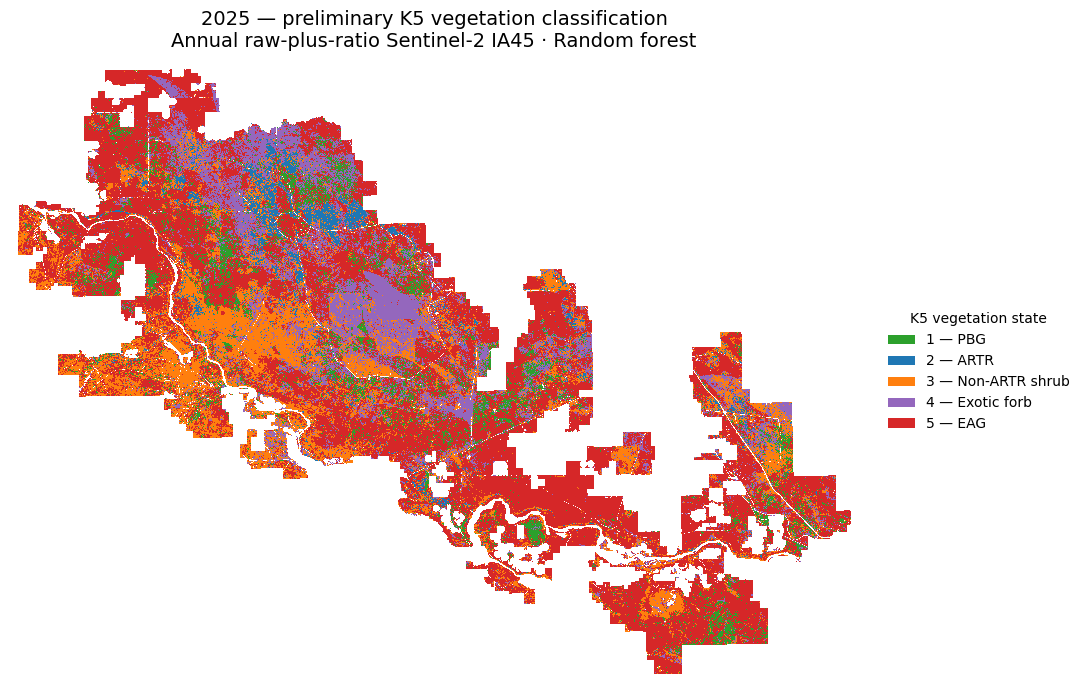

In [24]:
# =============================================================================
# DISPLAY ANNUAL K5 RANDOM-FOREST MAPS — TRUE NCA ONLY
# =============================================================================

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from rasterio.features import geometry_mask


# -----------------------------------------------------------------------------
# PATHS / SETTINGS
# -----------------------------------------------------------------------------

MAP_DIR = Path(
    r"C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA75_K5"
)

NCA_BOUNDARY = Path(
    r"C:\NCA_DATA\templates\SRBOP_NCA_extent_26911.shp"
)

YEARS = list(
    range(
        2016,
        2026,
    )
)

MODEL_NAME = "random_forest"


# -----------------------------------------------------------------------------
# K5 ECOLOGICAL LABELS
# -----------------------------------------------------------------------------

K5_LABELS = {
    1: "PBG",
    2: "ARTR",
    3: "Non-ARTR shrub",
    4: "Exotic forb",
    5: "EAG",
}


# -----------------------------------------------------------------------------
# CATEGORICAL COLORS
#
# Easy to replace later with the final STEP palette.
# -----------------------------------------------------------------------------

tab10 = plt.get_cmap(
    "tab10"
)

K5_COLORS = {
    1: tab10(2),   # PBG
    2: tab10(0),   # ARTR
    3: tab10(1),   # Non-ARTR shrub
    4: tab10(4),   # Exotic forb
    5: tab10(3),   # EAG
}

cmap = ListedColormap(
    [
        K5_COLORS[i]
        for i in range(
            1,
            6,
        )
    ]
)

norm = BoundaryNorm(
    np.arange(
        0.5,
        6.5,
        1.0,
    ),
    cmap.N,
)


legend_handles = [
    Patch(
        facecolor=K5_COLORS[code],
        edgecolor="none",
        label=f"{code} — {K5_LABELS[code]}",
    )
    for code in range(
        1,
        6,
    )
]


# -----------------------------------------------------------------------------
# LOAD TRUE NCA BOUNDARY
# -----------------------------------------------------------------------------

nca = gpd.read_file(
    NCA_BOUNDARY
)


# -----------------------------------------------------------------------------
# DISPLAY EACH YEAR
# -----------------------------------------------------------------------------

for year in YEARS:

    raster_path = (
        MAP_DIR
        / f"K5_RawPlusRatios_{MODEL_NAME}_{year}_class.tif"
    )


    if not raster_path.exists():

        print(
            f"{year}: raster not found — skipping"
        )

        continue


    with rasterio.open(
        raster_path
    ) as src:

        arr = src.read(
            1
        )

        transform = src.transform

        bounds = src.bounds

        raster_crs = src.crs


        # -------------------------------------------------------------
        # Reproject NCA boundary to raster CRS if necessary.
        # -------------------------------------------------------------

        nca_raster = nca.to_crs(
            raster_crs
        )


        # -------------------------------------------------------------
        # Exact polygon mask.
        # True inside NCA.
        # -------------------------------------------------------------

        inside_nca = geometry_mask(
            nca_raster.geometry,
            out_shape=arr.shape,
            transform=transform,
            invert=True,
        )


        # Mask nodata / outside true NCA.
        display_arr = np.ma.masked_where(
            (~inside_nca)
            | (arr == 0),
            arr,
        )


        # -------------------------------------------------------------
        # TRUE NCA DISPLAY EXTENT
        # -------------------------------------------------------------

        xmin, ymin, xmax, ymax = (
            nca_raster.total_bounds
        )

        xpad = (
            xmax
            - xmin
        ) * 0.01

        ypad = (
            ymax
            - ymin
        ) * 0.01


        # -------------------------------------------------------------
        # FIGURE
        # -------------------------------------------------------------

        fig, ax = plt.subplots(
            figsize=(
                11,
                7,
            )
        )


        ax.imshow(
            display_arr,
            cmap=cmap,
            norm=norm,
            extent=[
                bounds.left,
                bounds.right,
                bounds.bottom,
                bounds.top,
            ],
            origin="upper",
            interpolation="nearest",
        )


        ax.set_xlim(
            xmin - xpad,
            xmax + xpad,
        )

        ax.set_ylim(
            ymin - ypad,
            ymax + ypad,
        )


        ax.set_title(
            f"{year} — preliminary K5 vegetation classification\n"
            "Annual raw-plus-ratio Sentinel-2 IA45 · Random forest",
            fontsize=14,
            pad=12,
        )


        # -------------------------------------------------------------
        # CLEAN MAP APPEARANCE
        # -------------------------------------------------------------

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(
                False
            )


        ax.legend(
            handles=legend_handles,
            title="K5 vegetation state",
            loc="center left",
            bbox_to_anchor=(
                1.02,
                0.5,
            ),
            frameon=False,
        )


        plt.tight_layout()
        plt.show()
        plt.close(
            fig
        )


In [25]:
# =============================================================================
# K5 MAP STATISTICS — CLASS AREA, TEMPORAL AGREEMENT, UNCERTAINTY, ENDMEMBERS
# =============================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from rasterio.features import geometry_mask


# -----------------------------------------------------------------------------
# PATHS
# -----------------------------------------------------------------------------

MAP_DIR = Path(
    r"C:\NCA_DATA\Analysis\PrelimML_RawPlusRatios_IA75_K5"
)

NCA_BOUNDARY = Path(
    r"C:\NCA_DATA\templates\SRBOP_NCA_extent_26911.shp"
)

MODEL_NAME = "random_forest"

YEARS = list(
    range(
        2016,
        2026,
    )
)


K5_LABELS = {
    1: "PBG",
    2: "ARTR",
    3: "Non-ARTR shrub",
    4: "Exotic forb",
    5: "EAG",
}


# -----------------------------------------------------------------------------
# HIGH-CONFIDENCE / "ENDMEMBER" THRESHOLDS
#
# These are diagnostic thresholds, not calibrated probability statements.
# RF predict_proba values are relative classifier confidence.
# -----------------------------------------------------------------------------

PMAX_THRESHOLD = 0.80
MARGIN_THRESHOLD = 0.40

# Entropy normalized to [0,1] relative to five classes.
LOG_K = np.log(
    5.0
)


# -----------------------------------------------------------------------------
# LOAD TRUE NCA
# -----------------------------------------------------------------------------

nca = gpd.read_file(
    NCA_BOUNDARY
)


# -----------------------------------------------------------------------------
# STORAGE
# -----------------------------------------------------------------------------

annual_class_rows = []
annual_uncertainty_rows = []
class_uncertainty_rows = []
endmember_rows = []

class_arrays = {}
valid_masks = {}


# =============================================================================
# 1. ANNUAL MAP STATISTICS
# =============================================================================

for year in YEARS:

    class_path = (
        MAP_DIR
        / f"K5_RawPlusRatios_{MODEL_NAME}_{year}_class.tif"
    )

    uncertainty_path = (
        MAP_DIR
        / f"K5_RawPlusRatios_{MODEL_NAME}_{year}_uncertainty.tif"
    )


    if not class_path.exists():

        print(
            f"{year}: class raster missing — skipping"
        )

        continue


    with rasterio.open(
        class_path
    ) as src:

        classes = src.read(
            1
        )

        transform = src.transform

        raster_crs = src.crs

        pixel_area_m2 = abs(
            src.transform.a
            * src.transform.e
        )


        nca_raster = nca.to_crs(
            raster_crs
        )


        inside_nca = geometry_mask(
            nca_raster.geometry,
            out_shape=classes.shape,
            transform=transform,
            invert=True,
        )


        valid = (
            inside_nca
            & (
                classes
                > 0
            )
        )


    class_arrays[
        year
    ] = classes

    valid_masks[
        year
    ] = valid


    n_valid = int(
        valid.sum()
    )


    # -------------------------------------------------------------------------
    # CLASS COMPOSITION
    # -------------------------------------------------------------------------

    for code, label in K5_LABELS.items():

        class_mask = (
            valid
            & (
                classes
                == code
            )
        )

        n_pixels = int(
            class_mask.sum()
        )


        annual_class_rows.append(
            {
                "Year": year,
                "class_code": code,
                "class_label": label,
                "n_pixels": n_pixels,
                "fraction": (
                    n_pixels
                    / n_valid
                ),
                "percent": (
                    100.0
                    * n_pixels
                    / n_valid
                ),
                "area_km2": (
                    n_pixels
                    * pixel_area_m2
                    / 1e6
                ),
            }
        )


    # -------------------------------------------------------------------------
    # UNCERTAINTY
    # -------------------------------------------------------------------------

    if uncertainty_path.exists():

        with rasterio.open(
            uncertainty_path
        ) as src:

            pmax = src.read(
                1
            ).astype(
                np.float32
            )

            margin = src.read(
                2
            ).astype(
                np.float32
            )

            entropy = src.read(
                3
            ).astype(
                np.float32
            )


        uncertainty_valid = (
            valid
            & np.isfinite(
                pmax
            )
            & np.isfinite(
                margin
            )
            & np.isfinite(
                entropy
            )
            & (
                pmax
                >= 0
            )
            & (
                margin
                >= 0
            )
            & (
                entropy
                >= 0
            )
        )


        normalized_entropy = (
            entropy
            / LOG_K
        )


        annual_uncertainty_rows.append(
            {
                "Year": year,
                "mean_pmax": np.mean(
                    pmax[
                        uncertainty_valid
                    ]
                ),
                "median_pmax": np.median(
                    pmax[
                        uncertainty_valid
                    ]
                ),
                "mean_margin": np.mean(
                    margin[
                        uncertainty_valid
                    ]
                ),
                "median_margin": np.median(
                    margin[
                        uncertainty_valid
                    ]
                ),
                "mean_normalized_entropy": np.mean(
                    normalized_entropy[
                        uncertainty_valid
                    ]
                ),
                "median_normalized_entropy": np.median(
                    normalized_entropy[
                        uncertainty_valid
                    ]
                ),
            }
        )


        # ---------------------------------------------------------------------
        # CLASS-SPECIFIC CONFIDENCE + ENDMEMBER AREA
        # ---------------------------------------------------------------------

        for code, label in K5_LABELS.items():

            class_mask = (
                uncertainty_valid
                & (
                    classes
                    == code
                )
            )


            n_class = int(
                class_mask.sum()
            )


            if n_class == 0:

                continue


            high_conf = (
                class_mask
                & (
                    pmax
                    >= PMAX_THRESHOLD
                )
                & (
                    margin
                    >= MARGIN_THRESHOLD
                )
            )


            n_high = int(
                high_conf.sum()
            )


            class_uncertainty_rows.append(
                {
                    "Year": year,
                    "class_code": code,
                    "class_label": label,
                    "n_pixels": n_class,
                    "mean_pmax": np.mean(
                        pmax[
                            class_mask
                        ]
                    ),
                    "median_pmax": np.median(
                        pmax[
                            class_mask
                        ]
                    ),
                    "mean_margin": np.mean(
                        margin[
                            class_mask
                        ]
                    ),
                    "median_margin": np.median(
                        margin[
                            class_mask
                        ]
                    ),
                    "mean_normalized_entropy": np.mean(
                        normalized_entropy[
                            class_mask
                        ]
                    ),
                }
            )


            endmember_rows.append(
                {
                    "Year": year,
                    "class_code": code,
                    "class_label": label,
                    "n_class_pixels": n_class,
                    "n_high_confidence": n_high,
                    "fraction_high_confidence": (
                        n_high
                        / n_class
                    ),
                    "percent_high_confidence": (
                        100.0
                        * n_high
                        / n_class
                    ),
                    "high_confidence_area_km2": (
                        n_high
                        * pixel_area_m2
                        / 1e6
                    ),
                }
            )


# =============================================================================
# 2. TEMPORAL AGREEMENT
# =============================================================================

agreement_rows = []
transition_records = []


available_years = sorted(
    class_arrays
)


for year_a, year_b in zip(
    available_years[:-1],
    available_years[1:],
):

    a = class_arrays[
        year_a
    ]

    b = class_arrays[
        year_b
    ]


    valid = (
        valid_masks[
            year_a
        ]
        & valid_masks[
            year_b
        ]
    )


    aa = a[
        valid
    ]

    bb = b[
        valid
    ]


    agreement = np.mean(
        aa
        == bb
    )


    agreement_rows.append(
        {
            "year_from": year_a,
            "year_to": year_b,
            "n_pixels": len(
                aa
            ),
            "agreement": agreement,
            "percent_same": (
                100.0
                * agreement
            ),
            "percent_changed": (
                100.0
                * (
                    1.0
                    - agreement
                )
            ),
        }
    )


    # -------------------------------------------------------------------------
    # FULL TRANSITION MATRIX
    # -------------------------------------------------------------------------

    for from_code, from_label in K5_LABELS.items():

        from_mask = (
            aa
            == from_code
        )

        n_from = int(
            from_mask.sum()
        )


        if n_from == 0:

            continue


        for to_code, to_label in K5_LABELS.items():

            n_transition = int(
                np.sum(
                    from_mask
                    & (
                        bb
                        == to_code
                    )
                )
            )


            transition_records.append(
                {
                    "year_from": year_a,
                    "year_to": year_b,
                    "from_code": from_code,
                    "from_label": from_label,
                    "to_code": to_code,
                    "to_label": to_label,
                    "n_pixels": n_transition,
                    "fraction_of_from_class": (
                        n_transition
                        / n_from
                    ),
                }
            )


# =============================================================================
# 3. PER-PIXEL PERSISTENCE ACROSS ALL AVAILABLE YEARS
# =============================================================================

stack = np.stack(
    [
        class_arrays[
            year
        ]
        for year in available_years
    ],
    axis=0,
)


common_valid = np.logical_and.reduce(
    [
        valid_masks[
            year
        ]
        for year in available_years
    ]
)


stack_valid = stack[
    :,
    common_valid
]


# Number of year-to-year class changes per pixel.
n_changes = np.sum(
    stack_valid[
        1:
    ]
    != stack_valid[
        :-1
    ],
    axis=0,
)


# Number of unique classes occupied through time.
n_unique = np.array(
    [
        len(
            np.unique(
                stack_valid[
                    :,
                    i
                ]
            )
        )
        for i in range(
            stack_valid.shape[
                1
            ]
        )
    ],
    dtype=np.uint8,
)


# Modal class and modal-class fraction.
modal_class = np.zeros(
    stack_valid.shape[
        1
    ],
    dtype=np.uint8,
)

modal_fraction = np.zeros(
    stack_valid.shape[
        1
    ],
    dtype=np.float32,
)


for i in range(
    stack_valid.shape[
        1
    ]
):

    counts = np.bincount(
        stack_valid[
            :,
            i
        ],
        minlength=6,
    )[
        1:
    ]

    modal_class[
        i
    ] = (
        np.argmax(
            counts
        )
        + 1
    )

    modal_fraction[
        i
    ] = (
        counts.max()
        / len(
            available_years
        )
    )


persistence_summary = pd.DataFrame(
    {
        "metric": [
            "n_common_pixels",
            "mean_year_to_year_changes",
            "median_year_to_year_changes",
            "fraction_never_changes",
            "fraction_one_class_only",
            "mean_modal_fraction",
            "fraction_modal_ge_0p80",
        ],
        "value": [
            stack_valid.shape[
                1
            ],
            np.mean(
                n_changes
            ),
            np.median(
                n_changes
            ),
            np.mean(
                n_changes
                == 0
            ),
            np.mean(
                n_unique
                == 1
            ),
            np.mean(
                modal_fraction
            ),
            np.mean(
                modal_fraction
                >= 0.80
            ),
        ],
    }
)


# =============================================================================
# 4. TABLES
# =============================================================================

annual_class_df = pd.DataFrame(
    annual_class_rows
)

annual_uncertainty_df = pd.DataFrame(
    annual_uncertainty_rows
)

class_uncertainty_df = pd.DataFrame(
    class_uncertainty_rows
)

endmember_df = pd.DataFrame(
    endmember_rows
)

agreement_df = pd.DataFrame(
    agreement_rows
)

transition_df = pd.DataFrame(
    transition_records
)


print(
    "\n"
    + "=" * 90
)

print(
    "ANNUAL CLASS COMPOSITION (%)"
)

print(
    "=" * 90
)

display(
    annual_class_df.pivot(
        index="Year",
        columns="class_label",
        values="percent",
    )
    .round(
        1
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    "ANNUAL UNCERTAINTY"
)

print(
    "=" * 90
)

display(
    annual_uncertainty_df.round(
        3
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    "CLASS-SPECIFIC CONFIDENCE"
)

print(
    "=" * 90
)

display(
    class_uncertainty_df[
        [
            "Year",
            "class_label",
            "mean_pmax",
            "mean_margin",
            "mean_normalized_entropy",
        ]
    ].round(
        3
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    f"HIGH-CONFIDENCE ENDMEMBERS "
    f"(pmax ≥ {PMAX_THRESHOLD:.2f}, margin ≥ {MARGIN_THRESHOLD:.2f})"
)

print(
    "=" * 90
)

display(
    endmember_df.pivot(
        index="Year",
        columns="class_label",
        values="percent_high_confidence",
    )
    .round(
        1
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    "CONSECUTIVE-YEAR MAP AGREEMENT"
)

print(
    "=" * 90
)

display(
    agreement_df.round(
        2
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    "WHOLE-PERIOD PIXEL PERSISTENCE"
)

print(
    "=" * 90
)

display(
    persistence_summary
)


# =============================================================================
# 5. MEAN CLASS STATISTICS ACROSS YEARS
# =============================================================================

mean_class_stats = (
    annual_class_df
    .groupby(
        [
            "class_code",
            "class_label",
        ],
        as_index=False,
    )
    .agg(
        mean_percent=(
            "percent",
            "mean",
        ),
        sd_percent=(
            "percent",
            "std",
        ),
        min_percent=(
            "percent",
            "min",
        ),
        max_percent=(
            "percent",
            "max",
        ),
    )
)


mean_endmember_stats = (
    endmember_df
    .groupby(
        [
            "class_code",
            "class_label",
        ],
        as_index=False,
    )
    .agg(
        mean_percent_high_confidence=(
            "percent_high_confidence",
            "mean",
        ),
        min_percent_high_confidence=(
            "percent_high_confidence",
            "min",
        ),
        max_percent_high_confidence=(
            "percent_high_confidence",
            "max",
        ),
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    "MEAN ANNUAL CLASS COMPOSITION"
)

print(
    "=" * 90
)

display(
    mean_class_stats.round(
        2
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    "MEAN HIGH-CONFIDENCE FRACTION WITHIN EACH CLASS"
)

print(
    "=" * 90
)

display(
    mean_endmember_stats.round(
        2
    )
)



ANNUAL CLASS COMPOSITION (%)


class_label,ARTR,EAG,Exotic forb,Non-ARTR shrub,PBG
Year,,,,,
2016,3.8,29.1,29.1,12.7,25.3
2017,2.4,28.1,23.9,19.7,25.9
2018,1.1,39.3,20.0,9.1,30.5
2019,1.0,66.9,11.6,17.3,3.2
2020,2.0,29.7,36.6,18.2,13.5
2021,4.3,8.9,42.0,33.4,11.4
2022,3.1,30.7,37.0,13.1,16.1
2023,5.1,30.3,25.6,29.7,9.3
2024,7.6,44.2,30.0,5.6,12.5



ANNUAL UNCERTAINTY


,Year,mean_pmax,median_pmax,mean_margin,median_margin,mean_normalized_entropy,median_normalized_entropy
0,2016,0.442,0.425,0.190,0.149,0.821,0.832
1,2017,0.425,0.407,0.169,0.130,0.832,0.844
2,2018,0.501,0.479,0.258,0.215,0.759,0.781
3,2019,0.477,0.444,0.257,0.207,0.809,0.854
4,2020,0.417,0.394,0.167,0.130,0.852,0.880
5,2021,0.395,0.387,0.122,0.101,0.863,0.872
6,2022,0.387,0.371,0.137,0.112,0.886,0.907
7,2023,0.424,0.403,0.176,0.136,0.851,0.876
8,2024,0.375,0.364,0.107,0.083,0.887,0.900
9,2025,0.507,0.461,0.279,0.206,0.754,0.815



CLASS-SPECIFIC CONFIDENCE


,Year,class_label,mean_pmax,mean_margin,mean_normalized_entropy
0,2016,PBG,0.411,0.134,0.830
1,2016,ARTR,0.394,0.131,0.875
2,2016,Non-ARTR shrub,0.395,0.148,0.879
3,2016,Exotic forb,0.454,0.206,0.821
4,2016,EAG,0.485,0.248,0.779
5,2017,PBG,0.408,0.130,0.824
6,2017,ARTR,0.405,0.108,0.844
7,2017,Non-ARTR shrub,0.391,0.136,0.876
8,2017,Exotic forb,0.433,0.202,0.851
9,2017,EAG,0.459,0.204,0.791


... (6 outputs left out)


MEAN ANNUAL CLASS COMPOSITION


,class_code,class_label,mean_percent,sd_percent,min_percent,max_percent
0,1,PBG,15.57,8.84,3.22,30.53
1,2,ARTR,3.43,2.00,0.98,7.61
2,3,Non-ARTR shrub,17.87,8.59,5.61,33.36
3,4,Exotic forb,27.17,9.73,11.62,42.03
4,5,EAG,35.95,15.80,8.92,66.90



MEAN HIGH-CONFIDENCE FRACTION WITHIN EACH CLASS


,class_code,class_label,mean_percent_high_confidence,min_percent_high_confidence,max_percent_high_confidence
0,1,PBG,0.06,0.0,0.47
1,2,ARTR,0.00,0.0,0.00
2,3,Non-ARTR shrub,0.02,0.0,0.18
3,4,Exotic forb,0.00,0.0,0.03
4,5,EAG,3.41,0.0,17.63


## Interpretation boundary

This is a **five-class classification experiment**, not evidence that K=5 is intrinsically superior to K=8 simply because its predictive metrics may be higher. The response task is coarser and therefore easier.

The relevant questions are:

1. How much does grouped OOF accuracy / balanced accuracy / macro F1 improve when predicting the independently supported K5 vegetation partition?
2. Does LOYO temporal transfer improve consistently across 2016, 2018, and 2025?
3. Which of the five coarse vegetation modes remain difficult to distinguish optically?
4. Does the coarse K5 result support the hypothesis that Sentinel-2 harmonics observe major vegetation modes more reliably than the finer K8 intermediate/codominant structure?

The strongest comparison to the retained K8 classifier is therefore not raw accuracy alone, but the full confusion structure and transfer behavior at each ecological resolution.

2026 mapping is automatically enabled if the 2026 K2 raster exists. 2026 field observations contribute to training/evaluation only after both optical predictors and independently assigned K5 labels are available; regenerate the respective source CSVs. A new 2026 validation year is not a genuinely held-out prospective evaluation if used to refit the classifier.
